In [14]:
import numpy as np 
import pandas as pd 
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, accuracy_score, ConfusionMatrixDisplay
from sklearn.preprocessing import normalize , LabelEncoder
from sklearn.model_selection import train_test_split, KFold

from sklearn.decomposition import NMF


import tensorflow as tf
from tensorflow import keras    
from keras.layers import Dense, Dropout, Activation, Input
from tensorflow.keras.models import Model, Sequential
from keras.regularizers import l2
from keras.callbacks import EarlyStopping
import xgboost as xgb
from functions import *

In [15]:
test_data = pd.read_csv('https://raw.githubusercontent.com/paq88/Fish_neural_network_classifier/refs/heads/main/Gut_analysis/Data/clr_data_bacteria_gut.csv')
test_data

,Unnamed: 0,pond,d__Bacteria;p__Firmicutes;c__Bacilli;o__Erysipelotrichales;f__Erysipelotrichaceae,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Aeromonadales;f__Aeromonadaceae,d__Bacteria;p__Firmicutes;c__Clostridia;o__Clostridiales;f__Clostridiaceae,d__Bacteria;p__Firmicutes;c__Bacilli;o__Lactobacillales;f__Enterococcaceae,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Enterobacterales;f__Yersiniaceae,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;__;__,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Enterobacterales;f__Enterobacteriaceae,d__Bacteria;p__Fusobacteriota;c__Fusobacteriia;o__Fusobacteriales;f__Fusobacteriaceae,...,d__Bacteria;p__Firmicutes;c__Negativicutes;o__Veillonellales-Selenomonadales;f__Sporomusaceae,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Burkholderiales;f__Alcaligenaceae,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Vibrionales;f__Vibrionaceae,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Pseudomonadales;f__Moraxellaceae,d__Bacteria;p__Bacteroidota;c__Bacteroidia;o__Flavobacteriales;f__Crocinitomicaceae,d__Bacteria;p__Campilobacterota;c__Campylobacteria;o__Campylobacterales;f__Arcobacteraceae,d__Bacteria;p__Actinobacteriota;c__Actinobacteria;o__Actinomycetales;f__Actinomycetaceae,pond_5,pond_3,pond_2
0,0,Gut_S10,6.647672,6.589093,6.362286,5.114956,5.156017,4.557832,4.803711,5.316715,...,-1.101650,-1.101650,-1.101650,-1.101650,-1.101650,-1.101650,-1.101650,2,2,1
1,1,Gut_S10,7.159550,6.666644,4.905305,5.991671,5.962823,6.607497,3.235067,4.414870,...,-0.969625,-0.969625,-0.969625,-0.969625,-0.969625,-0.969625,-0.969625,2,2,1
2,2,Gut_S10,6.288459,7.950131,5.596058,4.723570,4.887873,3.247664,3.059072,6.288459,...,-0.911219,-0.911219,-0.911219,-0.911219,-0.911219,-0.911219,-0.911219,2,2,1
3,3,Gut_S10,6.603987,8.891680,4.065224,5.459487,4.973483,1.028670,7.374014,5.026870,...,-0.763090,-0.763090,-0.763090,-0.763090,-0.763090,-0.763090,-0.763090,2,2,1
4,4,Gut_S10,6.671165,7.648916,5.677504,1.461679,2.021295,1.867144,3.509372,5.371199,...,-0.617762,-0.617762,-0.617762,-0.617762,-0.617762,-0.617762,-0.617762,2,2,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
119,119,Gut_S9,4.248145,8.790730,4.276315,2.638707,1.791409,4.025001,0.980479,4.126784,...,-0.405816,-0.405816,-0.405816,-0.405816,-0.405816,-0.405816,-0.405816,3,1,0
120,120,Gut_S9,5.952408,7.486939,5.378375,5.276423,4.836334,4.118495,8.368655,5.344718,...,-0.668997,-0.668997,-0.668997,-0.668997,-0.668997,-0.668997,-0.668997,3,1,0
121,121,Gut_S9,4.691717,6.517318,4.382056,4.780086,4.140221,1.961688,8.947561,4.305095,...,-0.523219,-0.523219,-0.523219,-0.523219,-0.523219,-0.523219,-0.523219,3,1,0
122,122,Gut_S9,5.780981,4.708501,1.781762,4.050445,3.516363,0.683149,9.636186,3.789230,...,-0.415463,-0.415463,-0.415463,-0.415463,-0.415463,-0.415463,-0.415463,3,1,0


In [16]:
kf = KFold(n_splits=5, shuffle=True, random_state=111)

In [17]:
# data read and types check
df = pd.read_csv('https://raw.githubusercontent.com/paq88/Deep-Learning-in-classification-of-common-Carp-intestine-classification/refs/heads/main/Data/Gut_bacteria_merged.csv')
print(df.shape)
print(df.dtypes)
df.head()

(124, 127)
pond                                                                                           object
d__Bacteria;p__Firmicutes;c__Bacilli;o__Erysipelotrichales;f__Erysipelotrichaceae             float64
d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Aeromonadales;f__Aeromonadaceae       float64
d__Bacteria;p__Firmicutes;c__Clostridia;o__Clostridiales;f__Clostridiaceae                    float64
d__Bacteria;p__Firmicutes;c__Bacilli;o__Lactobacillales;f__Enterococcaceae                    float64
                                                                                               ...   
d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Vibrionales;f__Vibrionaceae           float64
d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Pseudomonadales;f__Moraxellaceae      float64
d__Bacteria;p__Bacteroidota;c__Bacteroidia;o__Flavobacteriales;f__Crocinitomicaceae           float64
d__Bacteria;p__Campilobacterota;c__Campylobacteria;o__Campylobacterales

,pond,d__Bacteria;p__Firmicutes;c__Bacilli;o__Erysipelotrichales;f__Erysipelotrichaceae,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Aeromonadales;f__Aeromonadaceae,d__Bacteria;p__Firmicutes;c__Clostridia;o__Clostridiales;f__Clostridiaceae,d__Bacteria;p__Firmicutes;c__Bacilli;o__Lactobacillales;f__Enterococcaceae,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Enterobacterales;f__Yersiniaceae,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;__;__,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Enterobacterales;f__Enterobacteriaceae,d__Bacteria;p__Fusobacteriota;c__Fusobacteriia;o__Fusobacteriales;f__Fusobacteriaceae,d__Bacteria;p__Bacteroidota;c__Bacteroidia;o__Bacteroidales;f__Dysgonomonadaceae,...,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Alteromonadales;f__Alteromonadaceae,d__Bacteria;p__Acidobacteriota;c__Vicinamibacteria;o__Vicinamibacterales;f__uncultured,d__Bacteria;p__Verrucomicrobiota;c__Verrucomicrobiae;o__Pedosphaerales;f__Pedosphaeraceae,d__Bacteria;p__Firmicutes;c__Negativicutes;o__Veillonellales-Selenomonadales;f__Sporomusaceae,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Burkholderiales;f__Alcaligenaceae,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Vibrionales;f__Vibrionaceae,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Pseudomonadales;f__Moraxellaceae,d__Bacteria;p__Bacteroidota;c__Bacteroidia;o__Flavobacteriales;f__Crocinitomicaceae,d__Bacteria;p__Campilobacterota;c__Campylobacteria;o__Campylobacterales;f__Arcobacteraceae,d__Bacteria;p__Actinobacteriota;c__Actinobacteria;o__Actinomycetales;f__Actinomycetaceae
0,Gut_S10,2319.0,2187.0,1743.0,500.0,521.0,286.0,366.0,612.0,160.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Gut_S10,3391.0,2071.0,355.0,1054.0,1024.0,1952.0,66.0,217.0,95.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Gut_S10,1338.0,7053.0,669.0,279.0,329.0,63.0,52.0,1338.0,139.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Gut_S10,1582.0,15595.0,124.0,503.0,309.0,5.0,3418.0,326.0,76.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Gut_S10,1463.0,3891.0,541.0,7.0,13.0,11.0,61.0,398.0,4.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [18]:
df = df.fillna(0)
df.head()

,pond,d__Bacteria;p__Firmicutes;c__Bacilli;o__Erysipelotrichales;f__Erysipelotrichaceae,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Aeromonadales;f__Aeromonadaceae,d__Bacteria;p__Firmicutes;c__Clostridia;o__Clostridiales;f__Clostridiaceae,d__Bacteria;p__Firmicutes;c__Bacilli;o__Lactobacillales;f__Enterococcaceae,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Enterobacterales;f__Yersiniaceae,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;__;__,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Enterobacterales;f__Enterobacteriaceae,d__Bacteria;p__Fusobacteriota;c__Fusobacteriia;o__Fusobacteriales;f__Fusobacteriaceae,d__Bacteria;p__Bacteroidota;c__Bacteroidia;o__Bacteroidales;f__Dysgonomonadaceae,...,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Alteromonadales;f__Alteromonadaceae,d__Bacteria;p__Acidobacteriota;c__Vicinamibacteria;o__Vicinamibacterales;f__uncultured,d__Bacteria;p__Verrucomicrobiota;c__Verrucomicrobiae;o__Pedosphaerales;f__Pedosphaeraceae,d__Bacteria;p__Firmicutes;c__Negativicutes;o__Veillonellales-Selenomonadales;f__Sporomusaceae,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Burkholderiales;f__Alcaligenaceae,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Vibrionales;f__Vibrionaceae,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Pseudomonadales;f__Moraxellaceae,d__Bacteria;p__Bacteroidota;c__Bacteroidia;o__Flavobacteriales;f__Crocinitomicaceae,d__Bacteria;p__Campilobacterota;c__Campylobacteria;o__Campylobacterales;f__Arcobacteraceae,d__Bacteria;p__Actinobacteriota;c__Actinobacteria;o__Actinomycetales;f__Actinomycetaceae
0,Gut_S10,2319.0,2187.0,1743.0,500.0,521.0,286.0,366.0,612.0,160.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,Gut_S10,3391.0,2071.0,355.0,1054.0,1024.0,1952.0,66.0,217.0,95.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,Gut_S10,1338.0,7053.0,669.0,279.0,329.0,63.0,52.0,1338.0,139.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,Gut_S10,1582.0,15595.0,124.0,503.0,309.0,5.0,3418.0,326.0,76.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,Gut_S10,1463.0,3891.0,541.0,7.0,13.0,11.0,61.0,398.0,4.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [19]:
print(df.shape)
df.describe()

(124, 127)


,d__Bacteria;p__Firmicutes;c__Bacilli;o__Erysipelotrichales;f__Erysipelotrichaceae,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Aeromonadales;f__Aeromonadaceae,d__Bacteria;p__Firmicutes;c__Clostridia;o__Clostridiales;f__Clostridiaceae,d__Bacteria;p__Firmicutes;c__Bacilli;o__Lactobacillales;f__Enterococcaceae,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Enterobacterales;f__Yersiniaceae,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;__;__,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Enterobacterales;f__Enterobacteriaceae,d__Bacteria;p__Fusobacteriota;c__Fusobacteriia;o__Fusobacteriales;f__Fusobacteriaceae,d__Bacteria;p__Bacteroidota;c__Bacteroidia;o__Bacteroidales;f__Dysgonomonadaceae,d__Bacteria;p__Firmicutes;c__Bacilli;o__Erysipelotrichales;f__Erysipelatoclostridiaceae,...,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Alteromonadales;f__Alteromonadaceae,d__Bacteria;p__Acidobacteriota;c__Vicinamibacteria;o__Vicinamibacterales;f__uncultured,d__Bacteria;p__Verrucomicrobiota;c__Verrucomicrobiae;o__Pedosphaerales;f__Pedosphaeraceae,d__Bacteria;p__Firmicutes;c__Negativicutes;o__Veillonellales-Selenomonadales;f__Sporomusaceae,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Burkholderiales;f__Alcaligenaceae,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Vibrionales;f__Vibrionaceae,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Pseudomonadales;f__Moraxellaceae,d__Bacteria;p__Bacteroidota;c__Bacteroidia;o__Flavobacteriales;f__Crocinitomicaceae,d__Bacteria;p__Campilobacterota;c__Campylobacteria;o__Campylobacterales;f__Arcobacteraceae,d__Bacteria;p__Actinobacteriota;c__Actinobacteria;o__Actinomycetales;f__Actinomycetaceae
count,124.000000,124.000000,124.000000,124.000000,124.000000,124.000000,124.000000,124.000000,124.000000,124.000000,...,124.000000,124.000000,124.000000,124.000000,124.000000,124.000000,124.000000,124.000000,124.000000,124.000000
mean,831.653226,8693.169355,171.370968,71.137097,105.548387,196.209677,677.419355,375.854839,53.169355,25.241935,...,0.096774,0.298387,0.080645,2.153226,0.217742,1.604839,0.153226,0.096774,0.266129,0.185484
std,1120.105607,5604.123141,224.484829,146.755443,192.490201,637.902078,2845.964849,456.780652,98.483354,67.552253,...,1.077632,2.270274,0.898027,20.938565,2.093585,13.805159,1.706250,1.077632,2.537872,2.065461
min,0.000000,167.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,106.750000,3913.500000,37.750000,0.000000,0.000000,6.750000,0.000000,55.500000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,469.500000,7454.500000,105.500000,2.000000,13.500000,27.500000,0.000000,211.000000,4.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,1037.750000,12774.000000,241.000000,91.500000,131.000000,118.250000,48.750000,467.250000,62.250000,15.250000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
max,6597.000000,26160.000000,1743.000000,1054.000000,1024.000000,5020.000000,23193.000000,2505.000000,581.000000,539.000000,...,12.000000,23.000000,10.000000,232.000000,23.000000,144.000000,19.000000,12.000000,28.000000,23.000000


In [20]:
predictors = df.columns[1:]
print(len(predictors))

126


X = W H 

## Transformation
In this approach we cannot use just CLR data as NMF expects only positive values so we applied shift 

In [21]:
# alternative - CLR + shift transformation 
#df[predictors] = pd.DataFrame(clr_manual(df[predictors]),columns = df[predictors].columns)
#f[predictors] = df[predictors] + abs(df[predictors].min().min()) + 0.00001

In [7]:
10e-6


1e-05

In [22]:
# log normalisation
df[predictors] = np.log1p(df[predictors]) + 0.00001


C:\Users\marek\AppData\Local\Temp\ipykernel_18496\2790385058.py:7: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


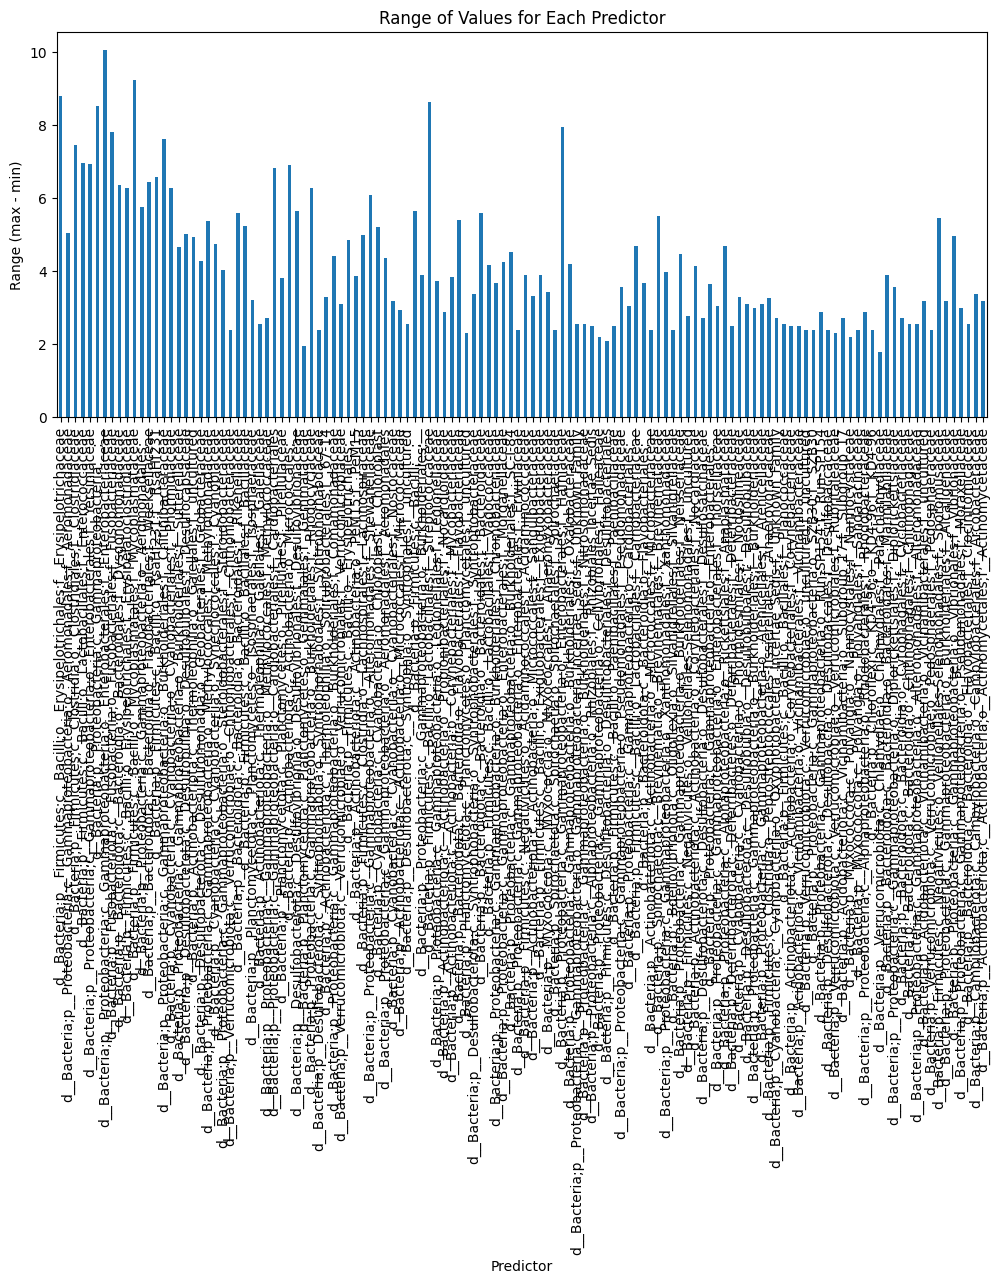

In [23]:
ranges = df[predictors].max() - df[predictors].min()
plt.figure(figsize=(12, 5))
ranges.plot(kind='bar')
plt.ylabel('Range (max - min)')
plt.xlabel('Predictor')
plt.title('Range of Values for Each Predictor')
plt.tight_layout()
plt.show()

## conversion of class variable


Explanation of pond coding
| number | setup | pond numbers | water supplementation | feed suplementation |
|---|---|---|---|---|
|0|control | 8,14,18,24,29|NO|NO|
|1|set 1 | 12,16,19,23,26|Em farma|NO|
|2|set 2 | 10,21,28,30,32|Em farma|EM|
|3|set 3 | 9,13,17,20,27|EM|NO|
|4|set 4 | 11,15,22,25,31|EM|EM|

In [24]:
codes = {0 : [8,14,18,24,29], 1: [12,16,19,23,26], 2 : [10,21,28,30,32], 3 : [9,13,17,20,27], 4 : [11,15,22,25,31]}
codes3 = {0 : [8,14,18,24,29], 1: [12,16,19,23,26,9,13,17,20,27], 2 : [10,21,28,30,32,11,15,22,25,31]}
codes2 = {0 : [8,14,18,24,29,12,16,19,23,26,9,13,17,20,27], 1 : [10,21,28,30,32,11,15,22,25,31]}

df['pond_5'] = df['pond'].apply(lambda x: pond_decoder(x,codes))
df['pond_3'] = df['pond'].apply(lambda x: pond_decoder(x,codes3))
df['pond_2'] = df['pond'].apply(lambda x: pond_decoder(x,codes2))

df = df.copy()


C:\Users\marek\AppData\Local\Temp\ipykernel_18496\1643662351.py:5: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['pond_5'] = df['pond'].apply(lambda x: pond_decoder(x,codes))
C:\Users\marek\AppData\Local\Temp\ipykernel_18496\1643662351.py:6: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['pond_3'] = df['pond'].apply(lambda x: pond_decoder(x,codes3))
C:\Users\marek\AppData\Local\Temp\ipykernel_18496\1643662351.py:7: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many

## Splitting data into train and test sets

In [25]:
df_train_val, df_test = train_test_split(df, test_size=0.2, random_state=111, stratify=df['pond_5'], shuffle=True)
df_train_val.shape, df_test.shape

((99, 130), (25, 130))

# Non negative Matrix Factorization

In [26]:
X = df_train_val[predictors].values

max_k = min(X.shape) 
errors = []
sds = []

for k in range(1, max_k + 1):
    print(f"Processing k={k}")
    nmf = NMF(n_components=k, init='nndsvda', random_state=42, max_iter=10000)
    W = nmf.fit_transform(X)
    H = nmf.components_
    
    # Reconstruction
    X_approx = W @ H
    # Frobenius norm reconstruction error
    error = np.mean(np.square(X - X_approx))
    errors.append(error)
    # Variance of the approximation
    sd = np.std(X_approx)
    sds.append(sd)

Processing k=1


C:\Users\marek\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\sklearn\decomposition\_nmf.py:1759: ConvergenceWarning: Maximum number of iterations 10000 reached. Increase it to improve convergence.
  warnings.warn(


Processing k=2
Processing k=3
Processing k=4
Processing k=5
Processing k=6
Processing k=7
Processing k=8
Processing k=9
Processing k=10
Processing k=11
Processing k=12
Processing k=13
Processing k=14
Processing k=15
Processing k=16
Processing k=17
Processing k=18
Processing k=19
Processing k=20
Processing k=21
Processing k=22
Processing k=23
Processing k=24
Processing k=25
Processing k=26
Processing k=27
Processing k=28
Processing k=29
Processing k=30
Processing k=31
Processing k=32
Processing k=33
Processing k=34
Processing k=35
Processing k=36
Processing k=37
Processing k=38
Processing k=39
Processing k=40
Processing k=41
Processing k=42
Processing k=43
Processing k=44
Processing k=45
Processing k=46
Processing k=47
Processing k=48
Processing k=49
Processing k=50
Processing k=51
Processing k=52
Processing k=53
Processing k=54
Processing k=55
Processing k=56
Processing k=57
Processing k=58
Processing k=59


C:\Users\marek\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\sklearn\decomposition\_nmf.py:1759: ConvergenceWarning: Maximum number of iterations 10000 reached. Increase it to improve convergence.
  warnings.warn(


Processing k=60
Processing k=61
Processing k=62


C:\Users\marek\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\sklearn\decomposition\_nmf.py:1759: ConvergenceWarning: Maximum number of iterations 10000 reached. Increase it to improve convergence.
  warnings.warn(


... (23 outputs left out)

C:\Users\marek\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\sklearn\decomposition\_nmf.py:1759: ConvergenceWarning: Maximum number of iterations 10000 reached. Increase it to improve convergence.
  warnings.warn(


Processing k=97
Processing k=98


C:\Users\marek\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\sklearn\decomposition\_nmf.py:1759: ConvergenceWarning: Maximum number of iterations 10000 reached. Increase it to improve convergence.
  warnings.warn(


Processing k=99


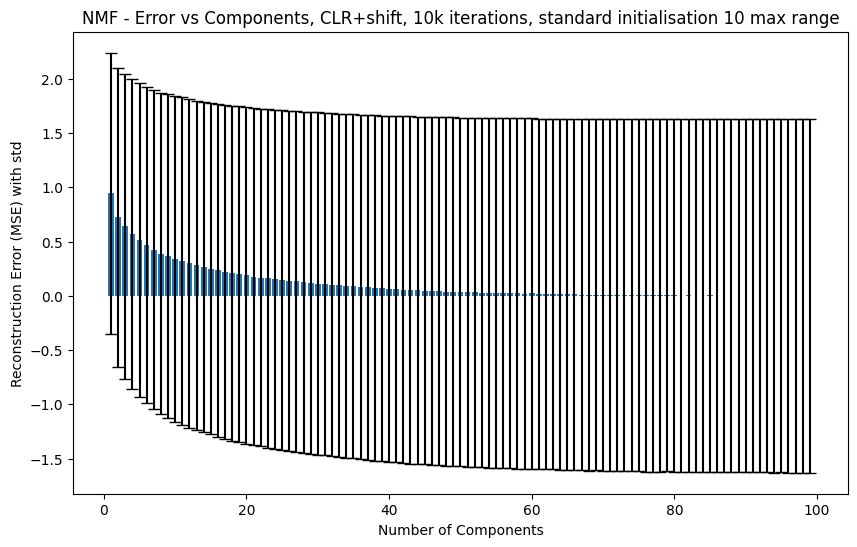

In [27]:
plt.figure(figsize=(10, 6))
bars = plt.bar(range(1, max_k + 1), errors, yerr=sds, capsize=4)
plt.xlabel('Number of Components')
plt.ylabel('Reconstruction Error (MSE) with std')
plt.title('NMF - Error vs Components, CLR+shift, 10k iterations, standard initialisation 10 max range')
plt.show()

Based on explained varianve approximation we can calculate the same threshold as was used in PCA of 90 to be 20 components

In [30]:
embeding_dim = 99
nmf = NMF(n_components=embeding_dim, init='nndsvdar', random_state=42, max_iter=10000)
W = nmf.fit_transform(df_train_val[predictors])
H = nmf.components_

reduced_train_X = nmf.fit_transform(df_train_val[predictors])
reduced_test_X= nmf.transform(df_test[predictors])

In [31]:
nmf100 = NMF(n_components=99, init='nndsvda', random_state=42, max_iter=10000)
H100 = nmf100.fit_transform(df_train_val[predictors])
W100 = nmf100.components_
X_approx100 = H100 @ W100
X_approx100 - df_train_val[predictors].values

array([[ 8.32718452e-06, -1.63559697e-05,  1.38453715e-06, ...,
        -7.64447105e-10, -1.35087043e-06,  1.25102751e-06],
       [-1.04784413e-04, -6.73026773e-05,  6.26878109e-06, ...,
        -1.82865882e-07, -9.99981912e-06, -9.99959695e-06],
       [-4.03513734e-05, -1.11169978e-05, -6.70581794e-06, ...,
         7.50424789e-09,  2.11148015e-06,  9.20597123e-04],
       ...,
       [ 5.51976623e-04, -1.07331149e-04,  4.52427494e-05, ...,
        -4.50948382e-08, -9.90514574e-06, -9.99986290e-06],
       [ 4.53049718e-04, -9.44546469e-06,  4.05722842e-05, ...,
        -1.52935163e-07,  4.35509605e-07,  3.59970497e-06],
       [ 1.74051745e-04,  5.46750885e-06,  5.46620173e-05, ...,
        -9.72399281e-09, -9.97264005e-06,  1.01319211e-04]])

In [32]:
approx_error = abs(X_approx100 - df_train_val[predictors].values)

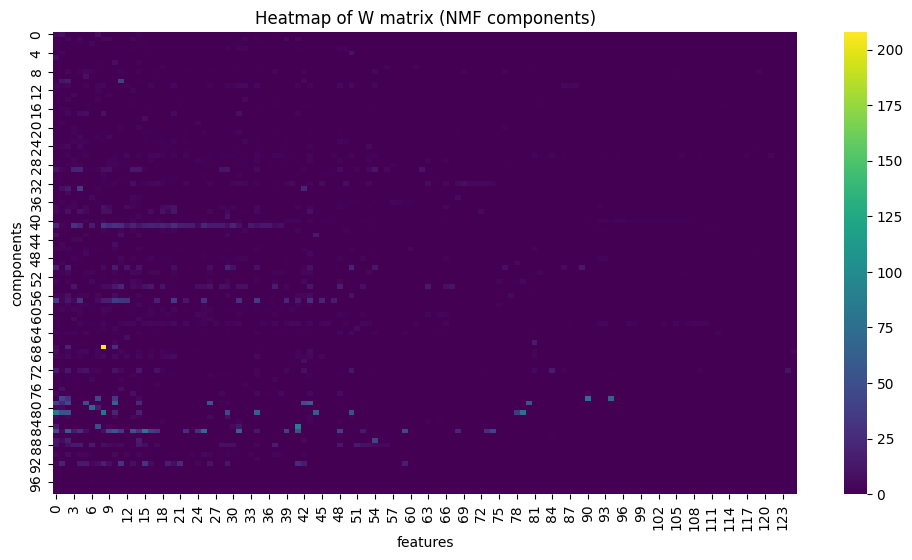

In [33]:
plt.figure(figsize=(12, 6))
sns.heatmap(H, cmap='viridis')
plt.title('Heatmap of W matrix (NMF components)')
plt.xlabel('features')
plt.ylabel('components')
plt.show()

Text(0.5, 1.0, 'H')

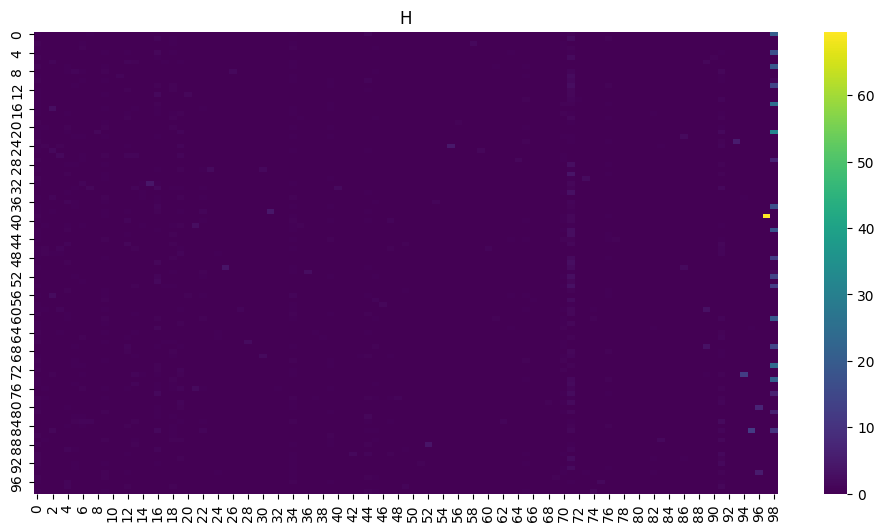

In [34]:
plt.figure(figsize=(12, 6))
sns.heatmap(W, cmap='viridis')
plt.title('H')

In [35]:
labels = df_train_val['pond_5']

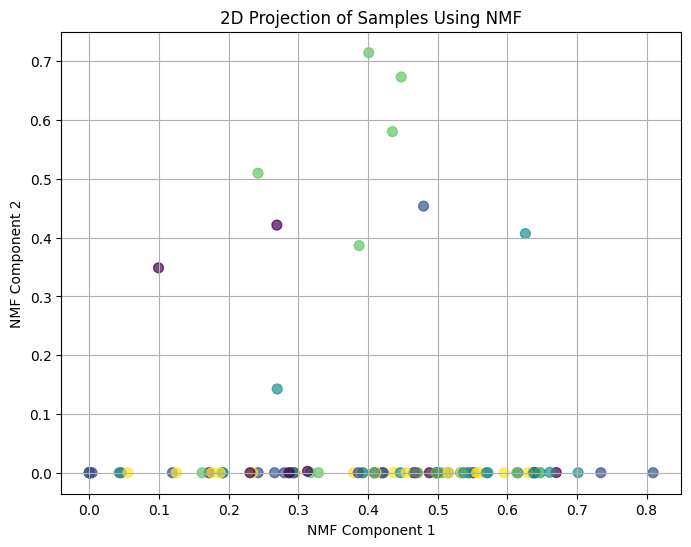

In [36]:
plt.figure(figsize=(8,6))
plt.scatter(W[:, 0], W[:, 1], c=labels, alpha=0.7, s=50)
plt.xlabel("NMF Component 1")
plt.ylabel("NMF Component 2")
plt.title("2D Projection of Samples Using NMF")
plt.grid(True)
plt.show()

In [87]:
def gini(v):
    a = np.sort(np.abs(v))
    n = a.size
    if a.sum() == 0: return 0.0
    return (2*np.arange(1,n+1)@a)/(n*a.sum()) - (n+1)/n

gini_vals = [gini(H[i]) for i in range(H.shape[0])]
gini_vals = np.array(gini_vals)

gini_threshold = 0.0

new_size = np.sum(gini_vals > gini_threshold)
print(f"Number of components with Gini > {gini_threshold}: {new_size}")
reduced_train_X_best = reduced_train_X[:, gini_vals > gini_threshold]
reduced_train_X_best.shape
embeding_dim = new_size
reduced_test_X_best = reduced_test_X[:, gini_vals > gini_threshold]



Number of components with Gini > 0.0: 99


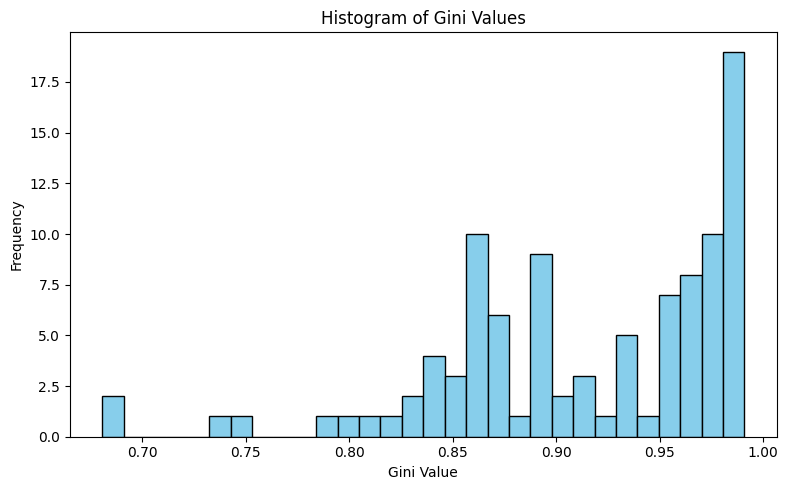

In [88]:
plt.figure(figsize=(8, 5))
plt.hist(gini_vals, bins=30, color='skyblue', edgecolor='black')
plt.xlabel('Gini Value')
plt.ylabel('Frequency')
plt.title('Histogram of Gini Values')
plt.tight_layout()
plt.show()

After this point there should be: 
- reduced train set (reduced_train_X) 
- reduced test set (reduced_test_X) to be compatible with next parts of notebook. 

Both in the form of Numpy array or pandas df but without Y(label) -- only X(predictors)

- embeding_dim should be specified which is number of column in descibet sets. 

In [89]:
reduced_df_train = pd.DataFrame(reduced_train_X_best, columns=[f'{i+1}' for i in range(embeding_dim)])
components = reduced_df_train.columns.to_list()
reduced_df_train['pond_5'] = df_train_val['pond_5'].reset_index(drop=True)
reduced_df_train['pond_3'] = df_train_val['pond_3'].reset_index(drop=True)
reduced_df_train['pond_2'] = df_train_val['pond_2'].reset_index(drop=True)
reduced_df_test = pd.DataFrame(reduced_test_X_best, columns=[f'{i+1}' for i in range(embeding_dim)])
reduced_df_test['pond_5'] = df_test['pond_5'].reset_index(drop=True)
reduced_df_test['pond_3'] = df_test['pond_3'].reset_index(drop=True)
reduced_df_test['pond_2'] = df_test['pond_2'].reset_index(drop=True)


print(components)

['1', '2', '3', '4', '5', '6', '7', '8', '9', '10', '11', '12', '13', '14', '15', '16', '17', '18', '19', '20', '21', '22', '23', '24', '25', '26', '27', '28', '29', '30', '31', '32', '33', '34', '35', '36', '37', '38', '39', '40', '41', '42', '43', '44', '45', '46', '47', '48', '49', '50', '51', '52', '53', '54', '55', '56', '57', '58', '59', '60', '61', '62', '63', '64', '65', '66', '67', '68', '69', '70', '71', '72', '73', '74', '75', '76', '77', '78', '79', '80', '81', '82', '83', '84', '85', '86', '87', '88', '89', '90', '91', '92', '93', '94', '95', '96', '97', '98', '99']


# 5 classes


In [90]:
target = 'pond_5'

## dense model 
fitting on embeded dataset


In [91]:
model5 = Sequential([
    Input(shape=(embeding_dim,)),
    Dense(32, activation='relu', kernel_regularizer=l2(0.02)),
    Dropout(0.25),
    Dense(32, activation='relu', kernel_regularizer=l2(0.02)),
    #Dense(32, activation='relu', kernel_regularizer=l2(0.02)),
    Dense(16, activation='relu', kernel_regularizer=l2(0.02)),
    Dense(5, activation='softmax')

])
model5.summary()
model5.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])


Model: "sequential_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_20 (Dense)                │ (None, 32)             │         3,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_21 (Dense)                │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_22 (Dense)                │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_23 (Dense)                │ (None, 5)              │            85 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,869 (19.02 KB)

 Trainable params: 4,869 (19.02 KB)

 Non-trainable params: 0 (0.00 B)

### Crossvalidation

Number of classes: 5
training for 1 subset
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 294ms/step - accuracy: 0.4000 - loss: 2.0211
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 104ms/step
predicted classes:       [1 3 0 2 2 4 3 0 3 3 0 1 3 4 4 3 4 1 2 2]
true validation classes: [3 3 1 2 2 0 1 1 3 1 1 4 2 4 0 2 4 1 3 2]
mean confidence score: 9.6981, sd confidence score: 11.4728
training for 2 subset
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - accuracy: 0.4000 - loss: 2.2034
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step
predicted classes:       [1 4 4 4 4 1 1 3 3 1 1 3 1 1 1 4 3 1 2 1]
true validation classes: [0 0 0 2 4 0 0 2 3 0 1 3 4 4 0 2 3 1 2 1]
mean confidence score: 9.5995, sd confidence score: 19.3449
training for 3 subset
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 86ms/step - accuracy: 0.3000 - loss: 3.1792
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step
predicted classes:       [3 3 2 3 1 0 3 1 4 0 1 1 1 3 2 1 1 4 4 1]
true validation classes: [1 1 2 2 0 4 0 3 0 4 3 1 4 2 2 1 3 1 4 1]
mean confidence score: 107.3066, sd confidence score: 393.9

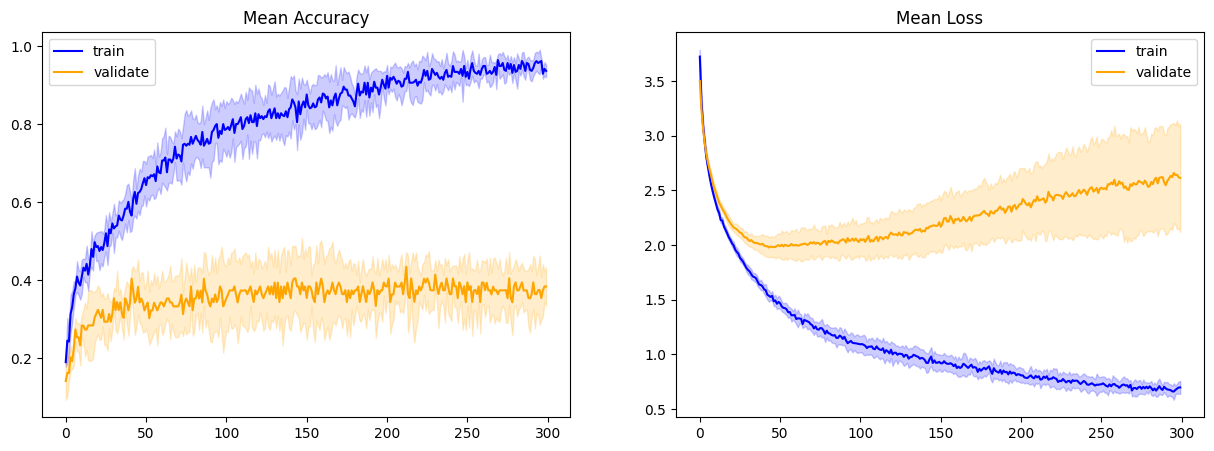

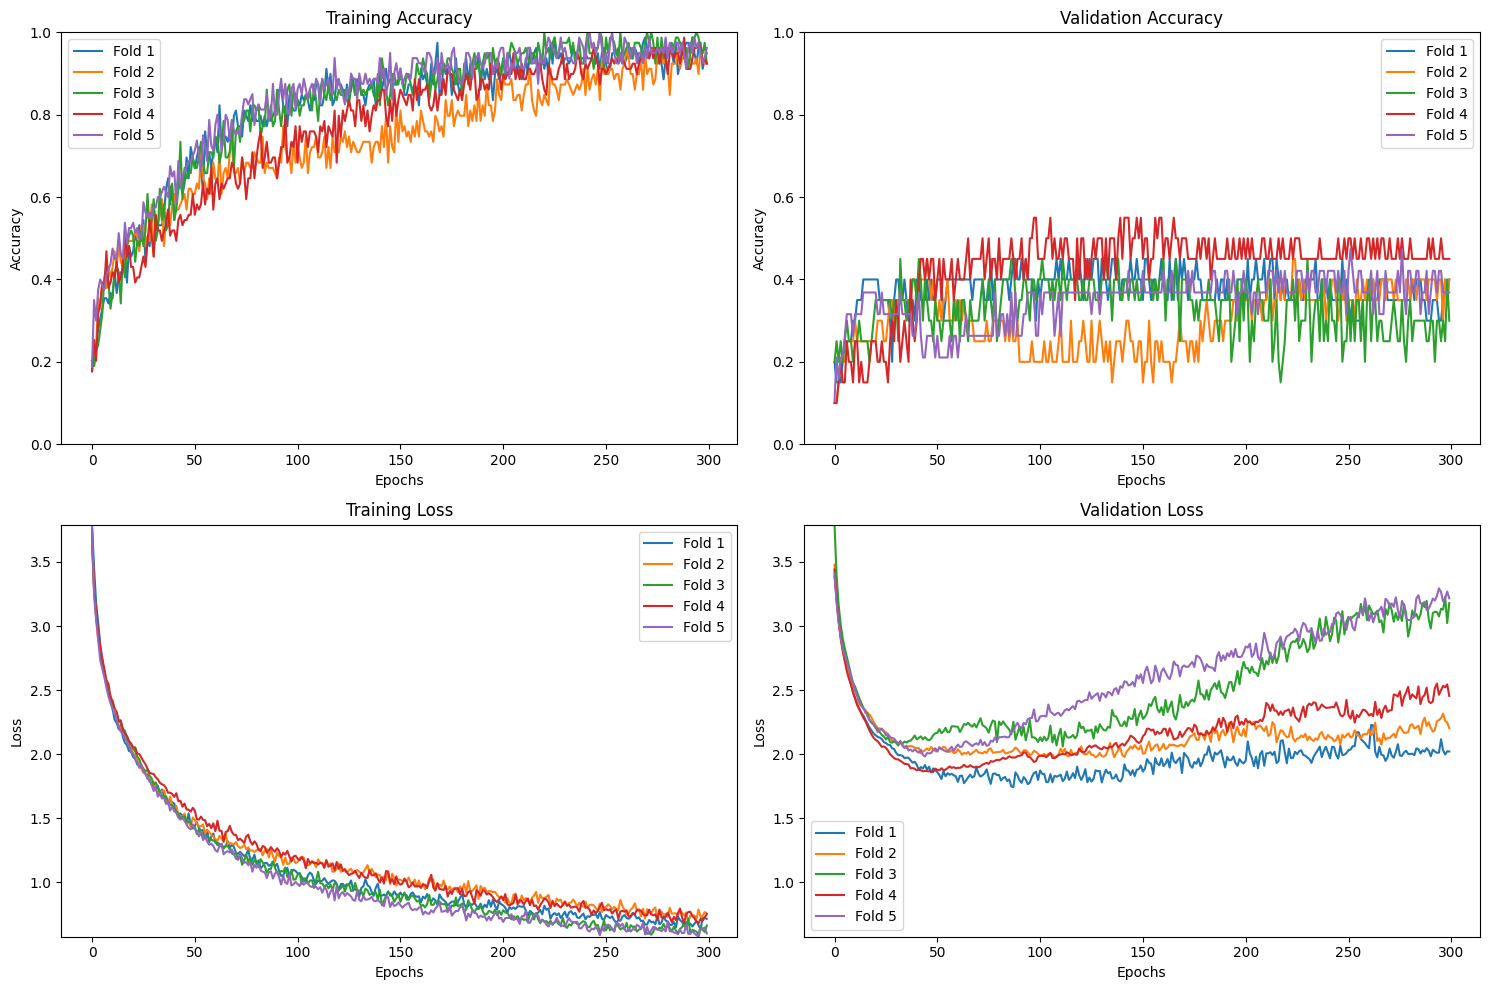

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step
predicted classes:       [1 2 4 2 4 3 3 4 4 0 4 4 4 1 4 0 0 0 4]
true validation classes: [4 0 4 2 2 0 3 1 2 0 2 4 4 3 3 4 1 0 3]


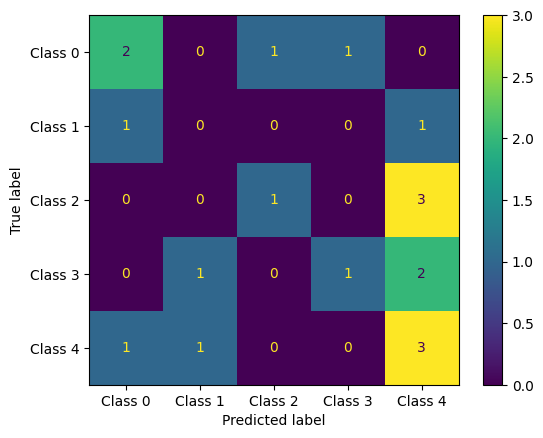

In [92]:
reset_weights(model5)
mean_acc_DNN_5_val, sd_acc_DNN_5_val = crossvalidate(reduced_df_train, model5, components, target, kf, 300)

### Test

In [93]:
X_train = reduced_df_train[components]
y_train = reduced_df_train[target]
y_train = keras.utils.to_categorical(y_train)

X_test = reduced_df_test[components]
y_test = reduced_df_test[target]
y_test = keras.utils.to_categorical(y_test)

Epoch 1/500


33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.2345 - loss: 3.6600 - val_accuracy: 0.2400 - val_loss: 3.1383
Epoch 2/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.2303 - loss: 3.1277 - val_accuracy: 0.1600 - val_loss: 2.8524
Epoch 3/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.2912 - loss: 2.8103 - val_accuracy: 0.2400 - val_loss: 2.6870
Epoch 4/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.4133 - loss: 2.6687 - val_accuracy: 0.2000 - val_loss: 2.5610
Epoch 5/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.3863 - loss: 2.5300 - val_accuracy: 0.1600 - val_loss: 2.4651
Epoch 6/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.4158 - loss: 2.4632 - val_accuracy: 0.2000 - val_loss: 2.3810
Epoch 7/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.3861 - loss: 2.3805 - val_accuracy: 0.1600 - val_loss: 2.3159
Epoch 8/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.4117 - loss: 2.2818 - val_accuracy: 0.1600 - val_loss: 2.

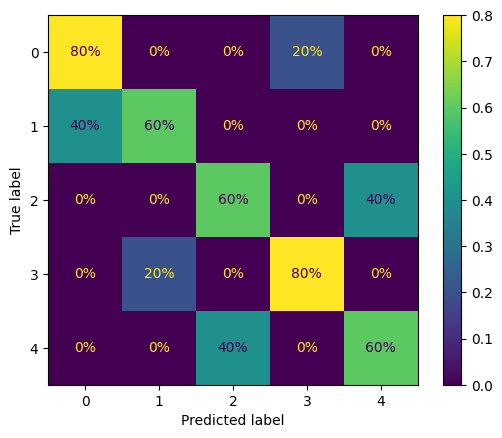

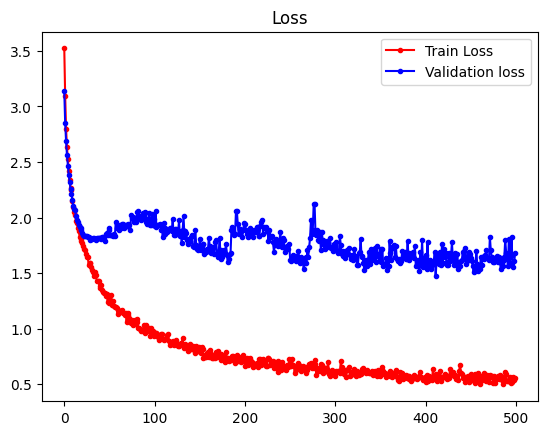

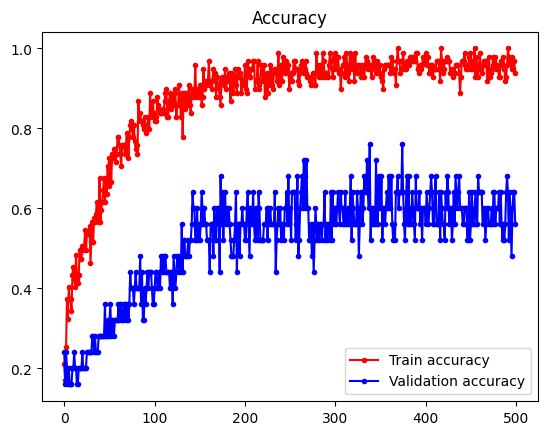

In [94]:
reset_weights(model5)
history5=model5.fit(X_train, y_train, epochs = 500, verbose = 1, shuffle = True, 
                    batch_size = 3, validation_data = (X_test, y_test), 
                    callbacks = [EarlyStopping(monitor='val_loss', patience=100, 
                                               restore_best_weights=True)])
acc_DNN_5_test = evaluate_model(model5, history5, X_test, y_test)

## Shallow model

In [95]:
model5_s = Sequential([
    Input(shape=(embeding_dim,)),
    Dense(17, activation='relu', kernel_regularizer=l2(0.03)),
    Dense(5, activation='softmax')
])
model5_s.summary()
model5_s.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])


Model: "sequential_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_24 (Dense)                │ (None, 17)             │         1,700 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_25 (Dense)                │ (None, 5)              │            90 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,790 (6.99 KB)

 Trainable params: 1,790 (6.99 KB)

 Non-trainable params: 0 (0.00 B)

### Crossvalidation

Number of classes: 5
training for 1 subset
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 386ms/step - accuracy: 0.5500 - loss: 1.5592
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 109ms/step
predicted classes:       [3 3 0 2 2 4 1 4 3 3 0 1 4 4 4 2 4 1 4 2]
true validation classes: [3 3 1 2 2 0 1 1 3 1 1 4 2 4 0 2 4 1 3 2]
mean confidence score: 9.2281, sd confidence score: 17.8309
training for 2 subset
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 78ms/step - accuracy: 0.3500 - loss: 1.9155
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step
predicted classes:       [3 4 4 1 4 1 1 3 3 1 1 3 3 1 1 4 0 1 2 1]
true validation classes: [0 0 0 2 4 0 0 2 3 0 1 3 4 4 0 2 3 1 2 1]
mean confidence score: 4.4153, sd confidence score: 2.9006
training for 3 subset
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step - accuracy: 0.3000 - loss: 2.8511
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step
predicted classes:       [3 3 3 3 1 4 3 0 2 4 1 1 1 3 2 1 0 4 2 1]
true validation classes: [1 1 2 2 0 4 0 3 0 4 3 1 4 2 2 1 3 1 4 1]
mean confidence score: 65.9843, sd confidence score: 255.516

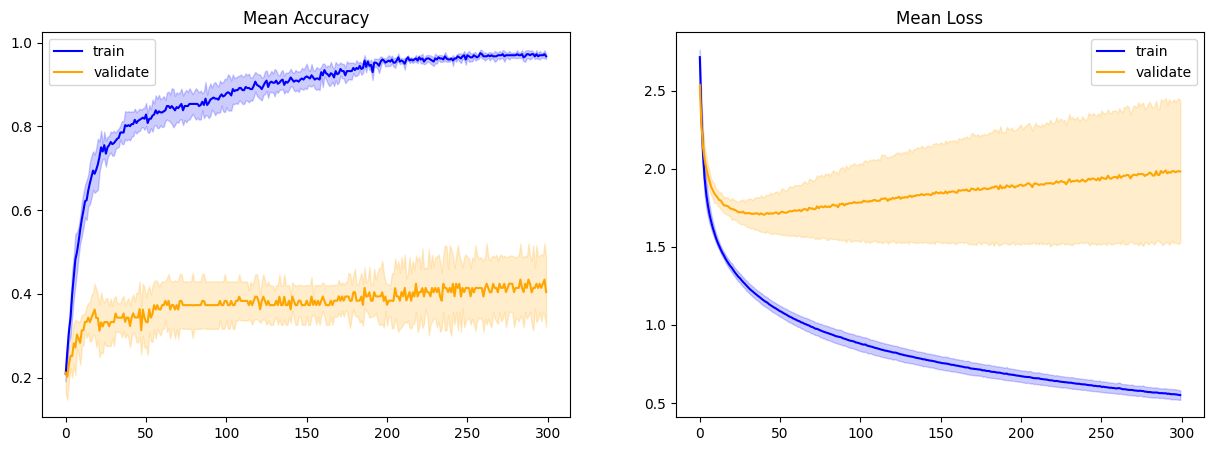

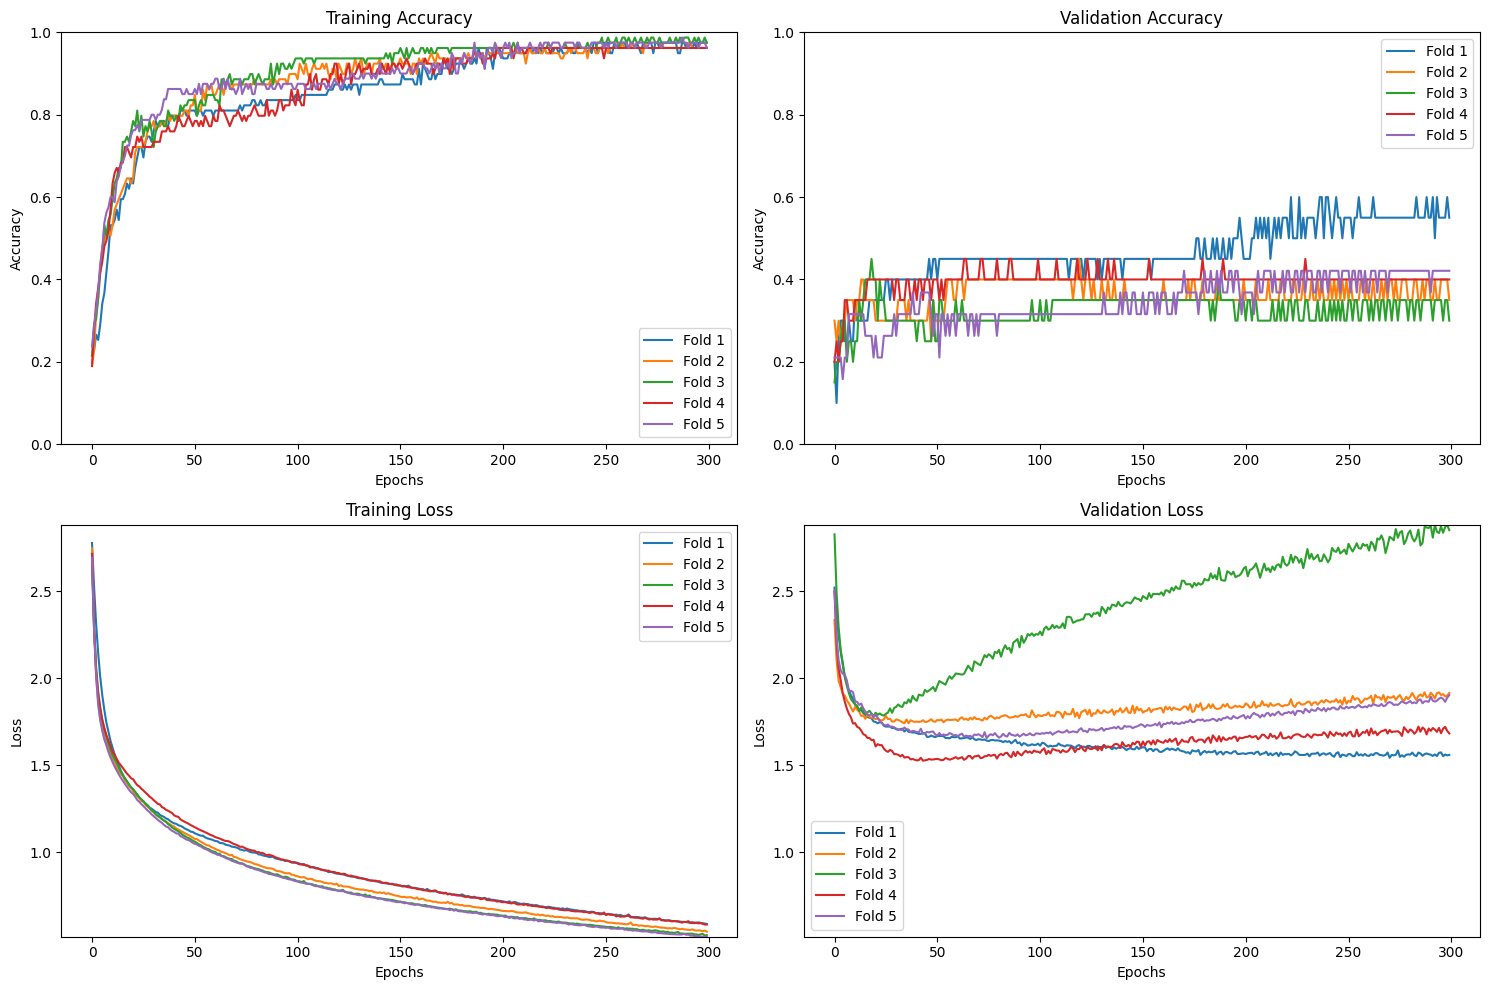

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step
predicted classes:       [4 2 4 2 4 4 3 4 4 0 4 2 4 3 2 0 0 0 2]
true validation classes: [4 0 4 2 2 0 3 1 2 0 2 4 4 3 3 4 1 0 3]


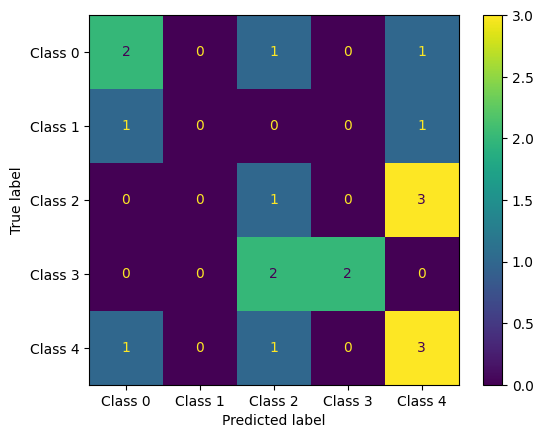

In [96]:
reset_weights(model5_s)
mean_acc_SNN_5_val, sd_acc_SNN_5_val = crossvalidate(reduced_df_train, model5_s, components, target,kf,300,True)


### Test    

In [97]:
X_train = reduced_df_train[components]
y_train = reduced_df_train[target]
y_train = keras.utils.to_categorical(y_train)

X_test = reduced_df_test[components]
y_test = reduced_df_test[target]
y_test = keras.utils.to_categorical(y_test)

In [98]:
model5_s.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

Epoch 1/500


33/33 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - accuracy: 0.8016 - loss: 0.9867 - val_accuracy: 0.3600 - val_loss: 1.4802
Epoch 2/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8933 - loss: 0.7494 - val_accuracy: 0.4400 - val_loss: 1.4496
Epoch 3/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8651 - loss: 0.7767 - val_accuracy: 0.4400 - val_loss: 1.4645
Epoch 4/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8769 - loss: 0.7415 - val_accuracy: 0.4400 - val_loss: 1.4078
Epoch 5/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8577 - loss: 0.6862 - val_accuracy: 0.4800 - val_loss: 1.4231
Epoch 6/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8634 - loss: 0.6640 - val_accuracy: 0.4400 - val_loss: 1.4269
Epoch 7/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8912 - loss: 0.6425 - val_accuracy: 0.4400 - val_loss: 1.4077
Epoch 8/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9149 - loss: 0.6559 - val_accuracy: 0.4400 - val_loss: 1.

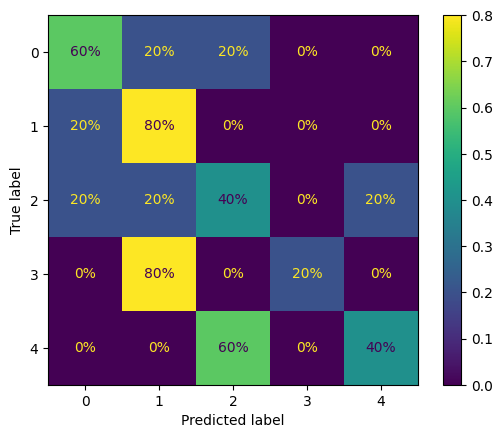

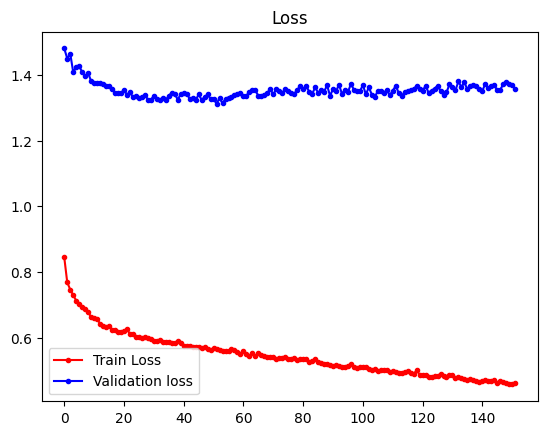

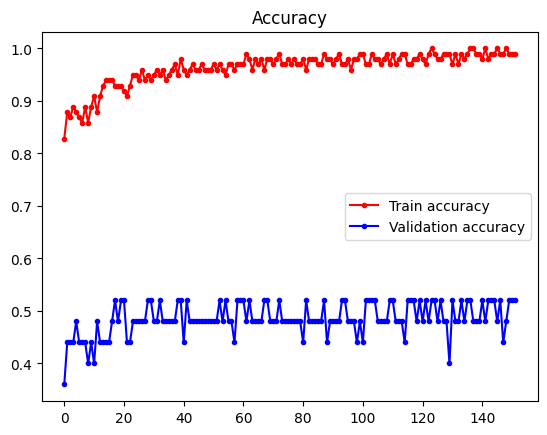

In [99]:
history5_s=model5_s.fit(X_train, y_train, epochs = 500, verbose = 1, 
                        shuffle = True, batch_size = 3, validation_data = (X_test, y_test), 
                        callbacks = [EarlyStopping(monitor='val_loss', patience=100, 
                                                   restore_best_weights=True)])
acc_SNN_5_test = evaluate_model(model5_s, history5_s, X_test, y_test)

## XGBoost

In [100]:
X_train.shape

(99, 99)

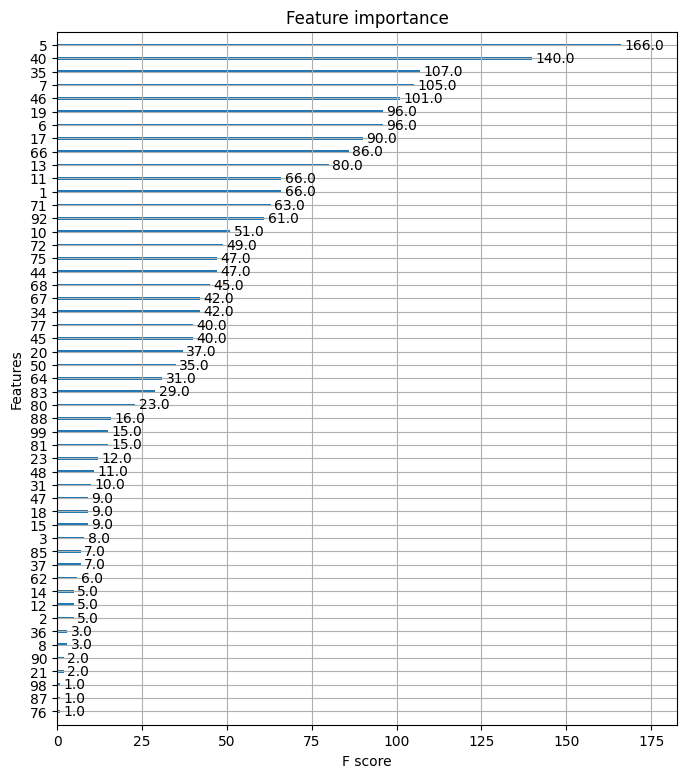

Accuracy0.48
true: [3 0 2 1 3 1 0 1 2 2 4 3 4 0 4 1 3 0 2 4 0 1 4 3 2]
predicted: [3. 4. 2. 3. 1. 0. 3. 1. 3. 4. 4. 0. 3. 0. 4. 4. 1. 0. 3. 4. 0. 1. 1. 3.
 2.]


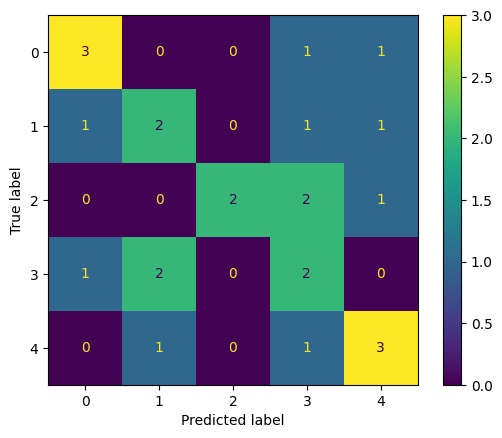

In [101]:
dtrain = xgb.DMatrix(X_train, label=df_train_val[target].values, feature_names=components)  
dtest = xgb.DMatrix(X_test, label=df_test[target].values, feature_names=components)
params = {
    'objective': 'multi:softmax',
    'num_class': 5,
    'max_depth': 3, 
    'eta': 0.1,
    'seed': 111
}

x2 = xgb.train(params, dtrain, num_boost_round=100)

xgb_pred = x2.predict(dtest)
xgb_acc = accuracy_score(df_test[target].values, xgb_pred)
acc_XGB_5_test = xgb_acc
fig, ax = plt.subplots(figsize=(8, 9))
xgb.plot_importance(x2, ax=ax)
plt.show()

print(f"Accuracy{xgb_acc}")
print(f"true: {df_test[target].values}")
print(f"predicted: {xgb_pred}")

cm = confusion_matrix(df_test[target].values, xgb_pred)
ConfusionMatrixDisplay(cm).plot()

# 3 Classes

In [102]:
target = 'pond_3'

## Dense model

In [103]:
model3 = Sequential([
     Input(shape=(embeding_dim,)),
    Dense(32, activation='relu', kernel_regularizer=l2(0.02)),
    Dropout(0.25),
    Dense(32, activation='relu', kernel_regularizer=l2(0.02)),
    #Dense(32, activation='relu', kernel_regularizer=l2(0.02)),
    Dense(16, activation='relu', kernel_regularizer=l2(0.02)),
    Dense(3, activation='softmax')
])


model3.summary()
model3.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])


Model: "sequential_9"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_26 (Dense)                │ (None, 32)             │         3,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_27 (Dense)                │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_28 (Dense)                │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_29 (Dense)                │ (None, 3)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,835 (18.89 KB)

 Trainable params: 4,835 (18.89 KB)

 Non-trainable params: 0 (0.00 B)

### Crossvalidation

Number of classes: 3
training for 1 subset
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 408ms/step - accuracy: 0.6000 - loss: 1.3230
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 111ms/step
predicted classes:       [1 1 0 2 2 2 1 2 1 1 0 1 1 2 2 2 2 1 2 2]
true validation classes: [1 1 1 2 2 0 1 1 1 1 1 2 2 2 0 2 2 1 1 2]
mean confidence score: 22.0509, sd confidence score: 37.4971
training for 2 subset
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step - accuracy: 0.4500 - loss: 2.0313
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step
predicted classes:       [1 2 2 2 2 1 1 1 0 0 2 1 1 1 0 2 0 1 2 1]
true validation classes: [0 0 0 2 2 0 0 2 1 0 1 1 2 2 0 2 1 1 2 1]
mean confidence score: 27.9764, sd confidence score: 66.1222
training for 3 subset
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - accuracy: 0.5500 - loss: 2.0458
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
predicted classes:       [1 1 1 1 1 2 2 1 1 2 1 1 0 1 2 1 0 2 2 1]
true validation classes: [1 1 2 2 0 2 0 1 0 2 1 1 2 2 2 1 1 1 2 1]
mean confidence score: 427.4581, sd confidence score: 114

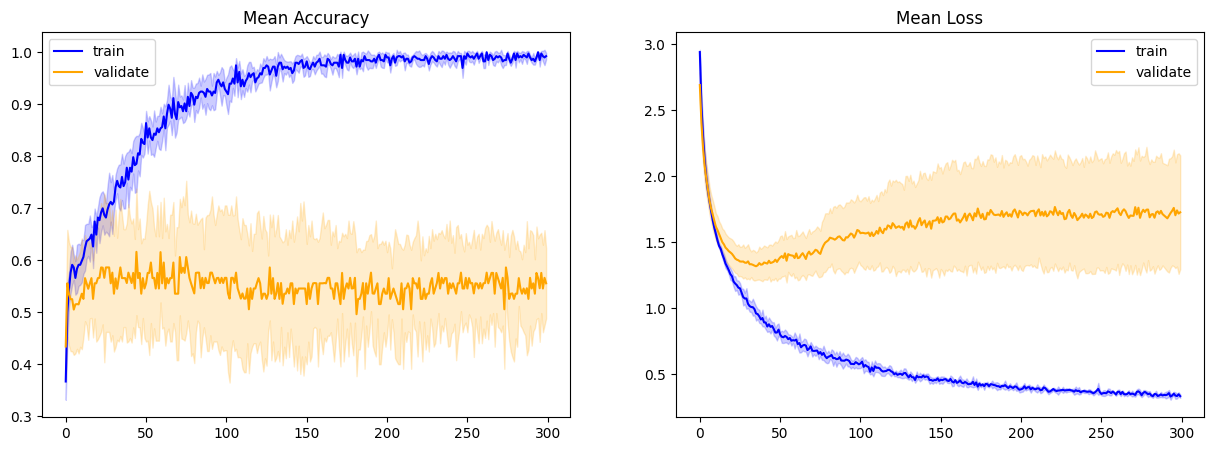

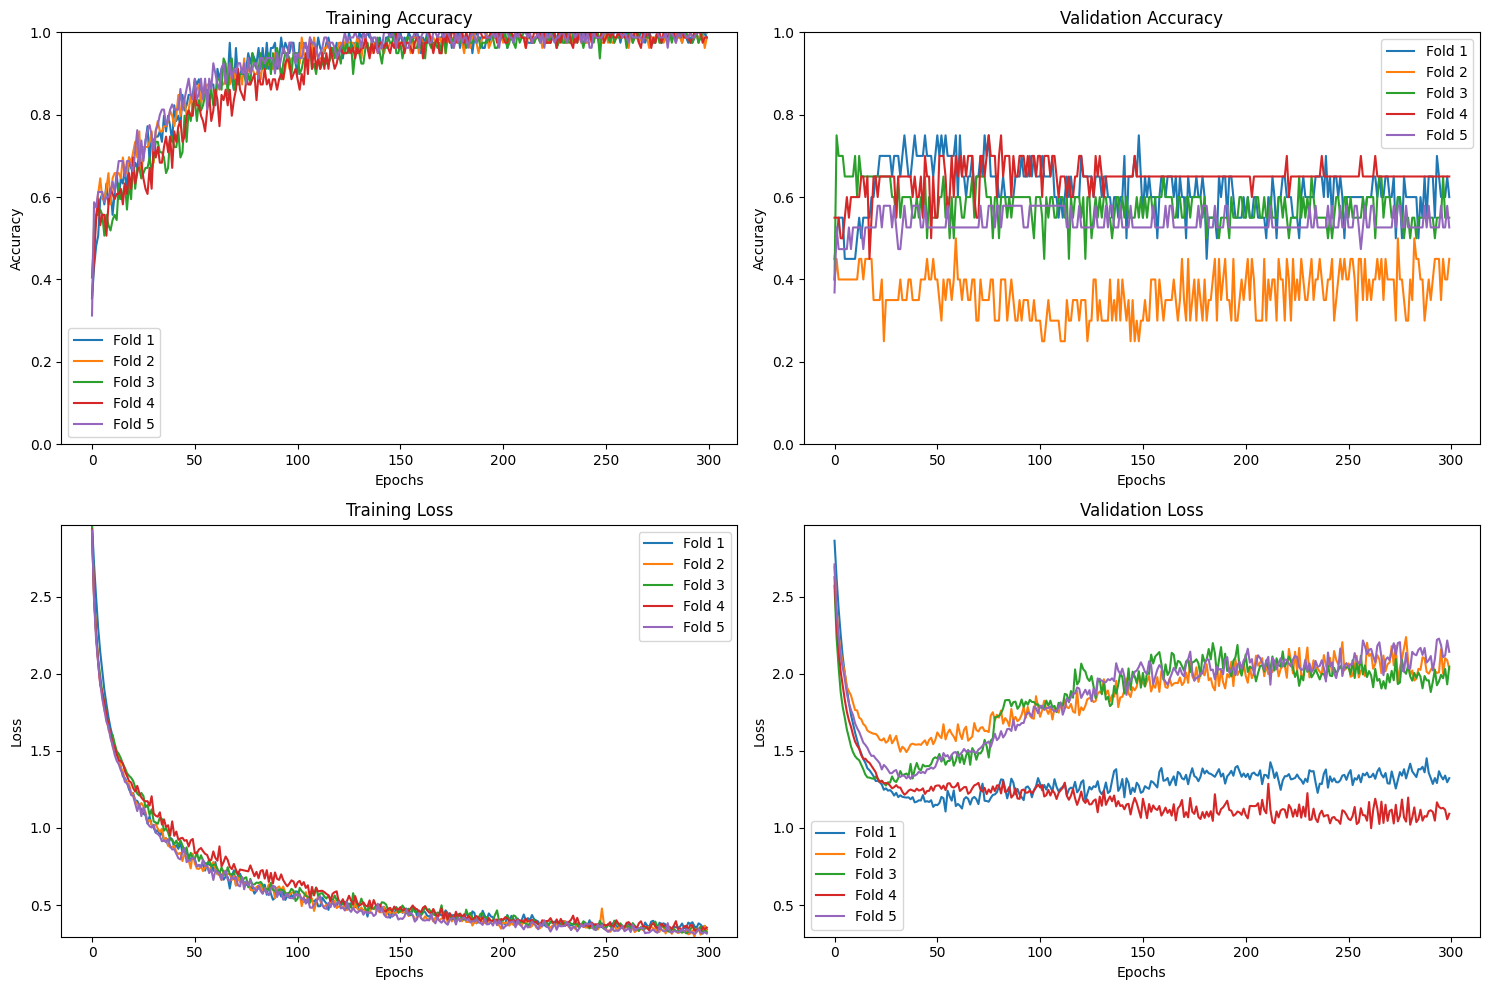

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
predicted classes:       [1 2 2 2 2 1 1 2 2 0 2 2 2 1 2 0 0 1 2]
true validation classes: [2 0 2 2 2 0 1 1 2 0 2 2 2 1 1 2 1 0 1]


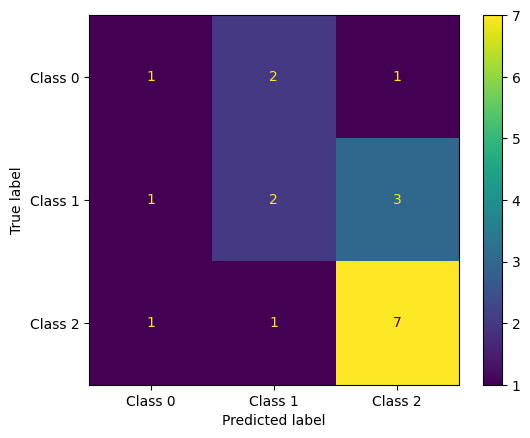

In [104]:
reset_weights(model3)
mean_acc_DNN_3_val, sd_acc_DNN_3_val = crossvalidate(reduced_df_train, model3, components, 'pond_3' ,kf,300)

### Test

In [105]:
X_train = reduced_df_train[components]
y_train = reduced_df_train[target]
y_train = keras.utils.to_categorical(y_train)

X_test = reduced_df_test[components]
y_test = reduced_df_test[target]
y_test = keras.utils.to_categorical(y_test)

Epoch 1/500


33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.4155 - loss: 2.8971 - val_accuracy: 0.4800 - val_loss: 2.3942
Epoch 2/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.4465 - loss: 2.2752 - val_accuracy: 0.4800 - val_loss: 2.0829
Epoch 3/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5457 - loss: 1.9929 - val_accuracy: 0.4800 - val_loss: 1.8979
Epoch 4/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6060 - loss: 1.7803 - val_accuracy: 0.4800 - val_loss: 1.7698
Epoch 5/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5993 - loss: 1.6871 - val_accuracy: 0.4800 - val_loss: 1.6807
Epoch 6/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6284 - loss: 1.6089 - val_accuracy: 0.4800 - val_loss: 1.6081
Epoch 7/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6060 - loss: 1.5659 - val_accuracy: 0.4800 - val_loss: 1.5482
Epoch 8/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6090 - loss: 1.4761 - val_accuracy: 0.4400 - val_loss: 1.4

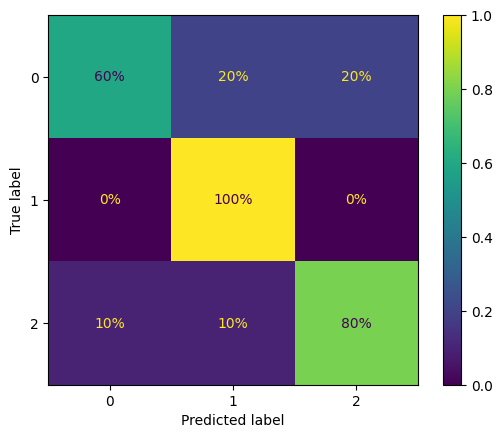

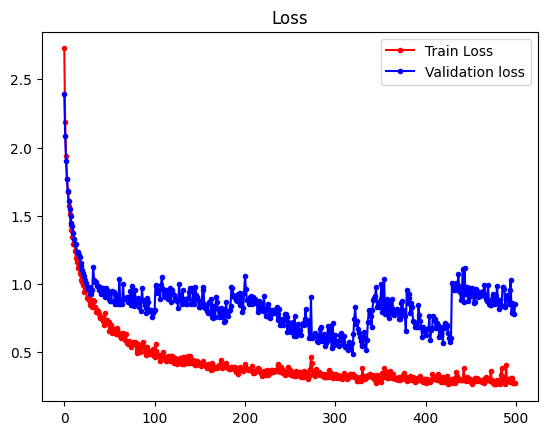

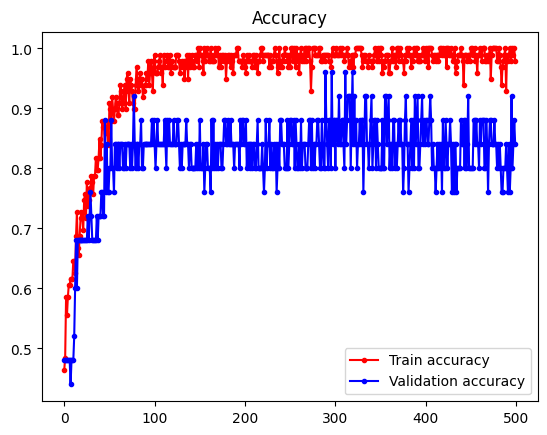

In [106]:
reset_weights(model3)
history3 = model3.fit(X_train, y_train, epochs = 500, verbose = 1, shuffle = True, batch_size = 3, validation_data = (X_test, y_test))
acc_DNN_3_test = evaluate_model(model3, history3, X_test, y_test)

## Shallow model 

In [107]:
model3_s = Sequential([
    Input(shape=(embeding_dim,)),
    Dense(17, activation='relu', kernel_regularizer=l2(0.01)),
    Dense(3, activation='softmax')
])
model3_s.summary()
model3_s.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])


Model: "sequential_10"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_30 (Dense)                │ (None, 17)             │         1,700 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_31 (Dense)                │ (None, 3)              │            54 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,754 (6.85 KB)

 Trainable params: 1,754 (6.85 KB)

 Non-trainable params: 0 (0.00 B)

### Crossvalidation

Number of classes: 3
training for 1 subset
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 155ms/step - accuracy: 0.7500 - loss: 1.1304
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step
predicted classes:       [1 1 0 2 2 2 1 1 1 1 1 1 2 2 2 2 2 1 2 2]
true validation classes: [1 1 1 2 2 0 1 1 1 1 1 2 2 2 0 2 2 1 1 2]
mean confidence score: 16.052, sd confidence score: 34.8542
training for 2 subset
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.3500 - loss: 1.9940
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
predicted classes:       [1 2 2 1 2 1 1 1 2 1 1 1 1 1 1 2 0 1 2 1]
true validation classes: [0 0 0 2 2 0 0 2 1 0 1 1 2 2 0 2 1 1 2 1]
mean confidence score: 17.6066, sd confidence score: 26.7329
training for 3 subset
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - accuracy: 0.6500 - loss: 1.5446
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
predicted classes:       [1 1 2 1 1 2 2 1 2 2 1 1 0 2 2 1 0 2 2 1]
true validation classes: [1 1 2 2 0 2 0 1 0 2 1 1 2 2 2 1 1 1 2 1]
mean confidence score: 1165261.821, sd confidence score: 50

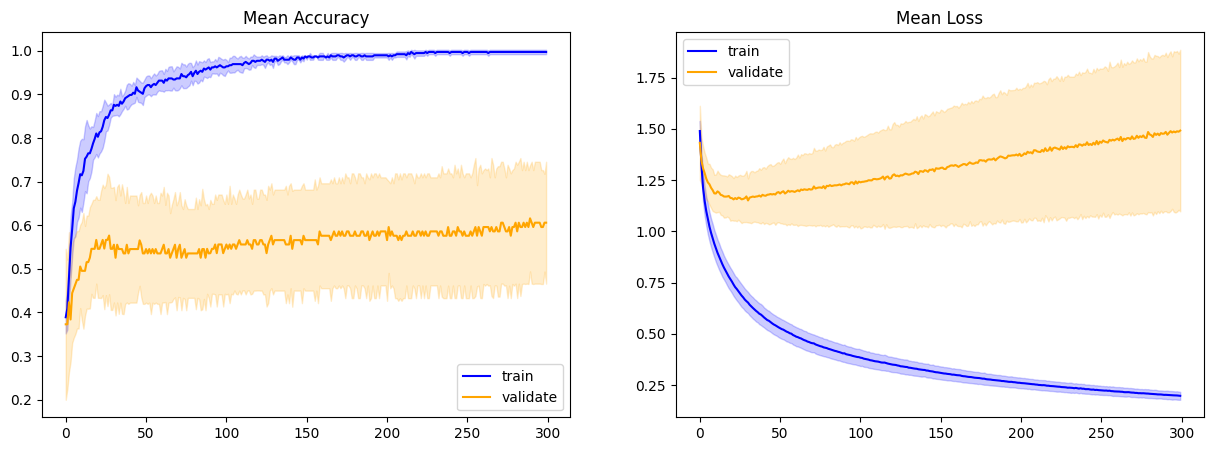

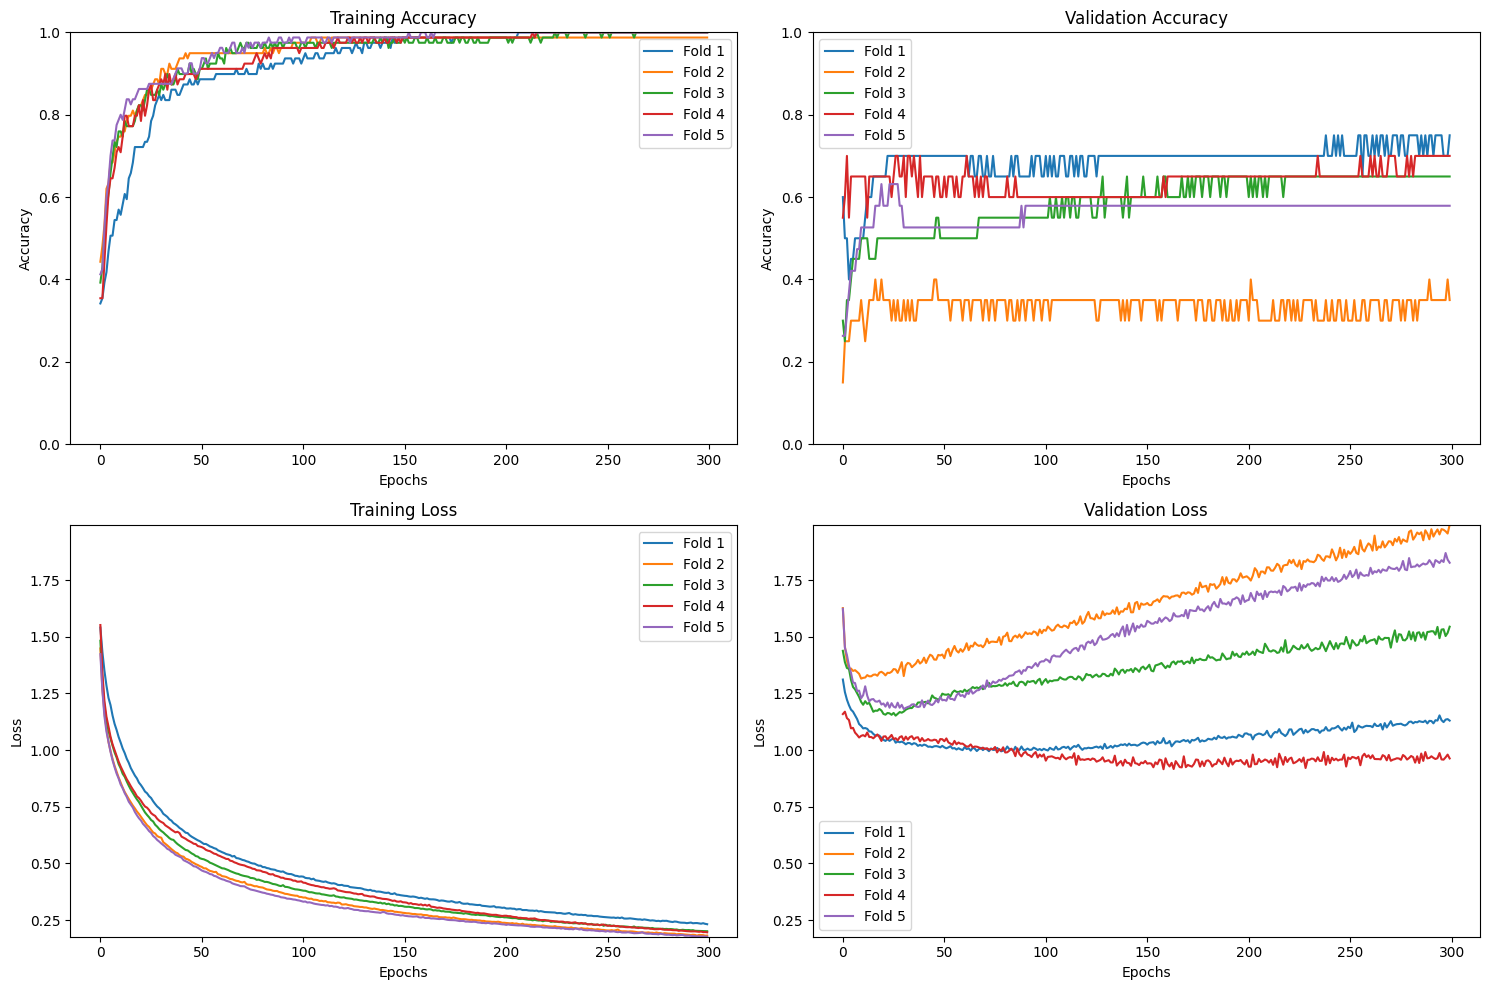

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
predicted classes:       [1 2 2 2 2 1 1 2 2 0 2 2 2 1 2 0 0 0 2]
true validation classes: [2 0 2 2 2 0 1 1 2 0 2 2 2 1 1 2 1 0 1]


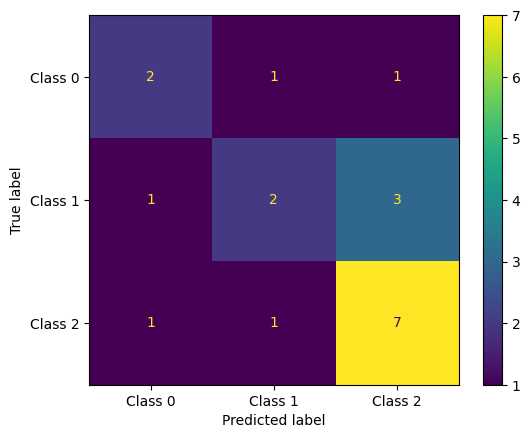

In [108]:
reset_weights(model3)
mean_acc_SNN_3_val, sd_acc_SNN_3_val = crossvalidate(reduced_df_train, model3_s, components, 'pond_3' ,kf,300)

### test

In [109]:
model3_s.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.9200 - loss: 0.3248
[0.3247770071029663, 0.9200000166893005]
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step
Predicted values: [1 2 2 1 1 1 0 1 2 2 2 1 2 0 2 1 1 0 2 2 1 1 2 1 2]
True values: [1 0 2 1 1 1 0 1 2 2 2 1 2 0 2 1 1 0 2 2 0 1 2 1 2]
Test accuracy: 0.800000011920929


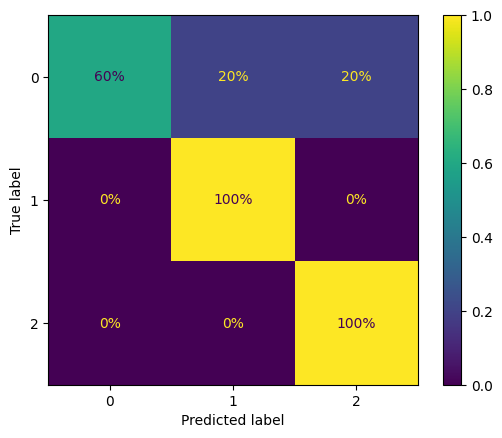

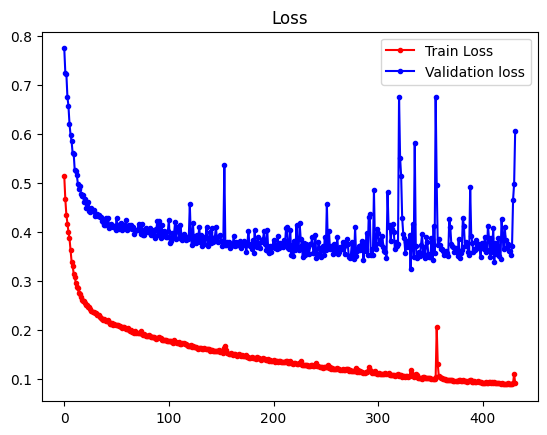

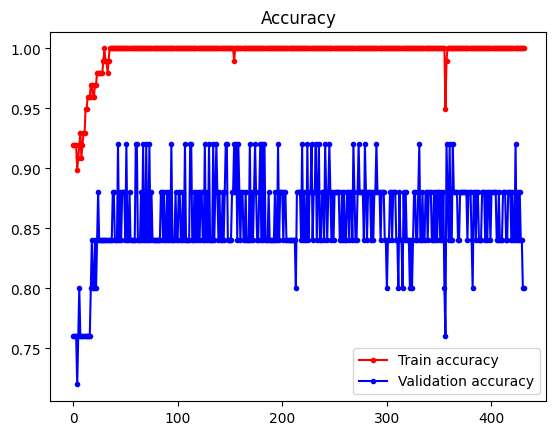

In [110]:
history3_s=model3_s.fit(X_train, y_train, epochs = 500, verbose = 0, shuffle = True, batch_size = 3, validation_data = (X_test, y_test), callbacks = [EarlyStopping(monitor='val_loss', patience=100, restore_best_weights=True)])
acc_SNN_3_test = evaluate_model(model3_s, history3_s, X_test, y_test)

## XGBoost

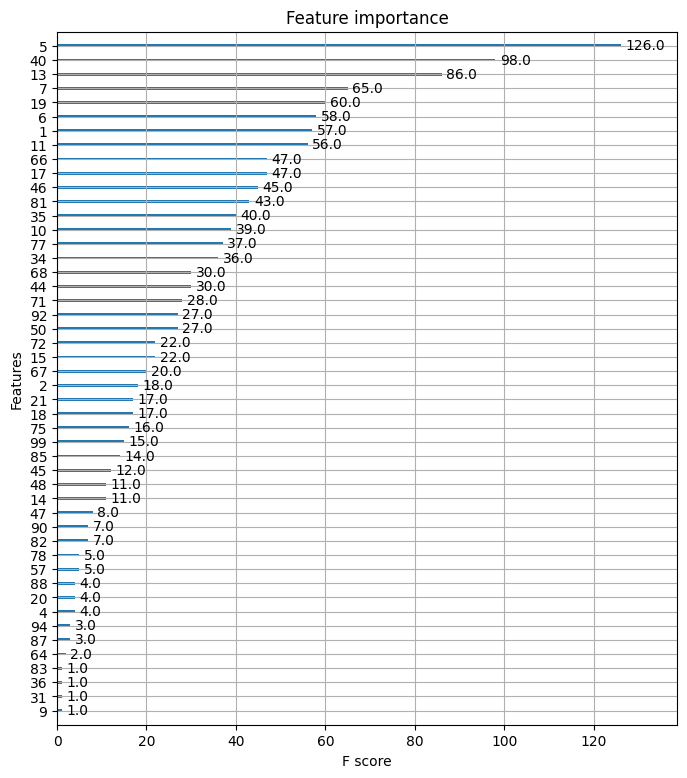

Accuracy0.8
true: [1 0 2 1 1 1 0 1 2 2 2 1 2 0 2 1 1 0 2 2 0 1 2 1 2]
predicted: [1. 2. 2. 1. 1. 0. 1. 1. 2. 2. 2. 2. 2. 0. 2. 1. 1. 0. 2. 2. 0. 1. 1. 1.
 2.]


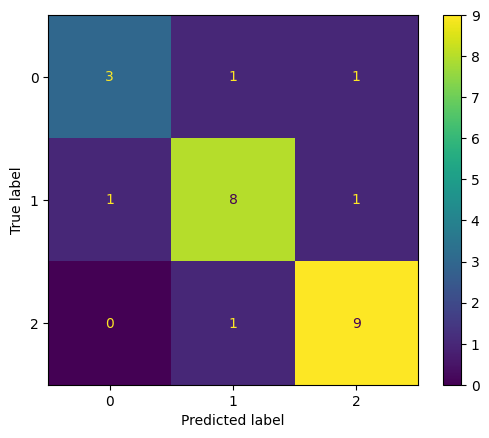

In [111]:
dtrain = xgb.DMatrix(X_train, label=df_train_val[target].values, feature_names=components)  
dtest = xgb.DMatrix(X_test, label=df_test[target].values, feature_names=components)
params = {
    'objective': 'multi:softmax',
    'num_class': 5,
    'max_depth': 3, 
    'eta': 0.1,
    'seed': 111
}

x2 = xgb.train(params, dtrain, num_boost_round=100)

xgb_pred = x2.predict(dtest)
xgb_acc = accuracy_score(df_test[target].values, xgb_pred)
acc_XGB_3_test = xgb_acc
fig, ax = plt.subplots(figsize=(8, 9))
xgb.plot_importance(x2, ax=ax)
plt.show()

print(f"Accuracy{xgb_acc}")
print(f"true: {df_test[target].values}")
print(f"predicted: {xgb_pred}")

cm = confusion_matrix(df_test[target].values, xgb_pred)
ConfusionMatrixDisplay(cm).plot()

# 2 Classes

In [112]:
target = 'pond_2'

## Dense model

In [113]:
X_train = reduced_df_train[components]
y_train = reduced_df_train[target]
y_train = keras.utils.to_categorical(y_train)

X_test = reduced_df_test[components]
y_test = reduced_df_test[target]
y_test = keras.utils.to_categorical(y_test)

In [114]:
model2 = Sequential([
    Input(shape=(embeding_dim,)),
    Dense(32, activation='relu', kernel_regularizer=l2(0.01)),
    Dropout(rate=0.25),
    Dense(32, activation='relu', kernel_regularizer=l2(0.01)),
    Dense(16, activation='relu', kernel_regularizer=l2(0.01)),
    Dense(2, activation='softmax')
])
model2.summary()
model2.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

Model: "sequential_11"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_32 (Dense)                │ (None, 32)             │         3,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_33 (Dense)                │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_34 (Dense)                │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_35 (Dense)                │ (None, 2)              │            34 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,818 (18.82 KB)

 Trainable params: 4,818 (18.82 KB)

 Non-trainable params: 0 (0.00 B)

### Crossvalidation

Number of classes: 2
training for 1 subset
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 175ms/step - accuracy: 0.7000 - loss: 1.2271
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step
predicted classes:       [0 0 0 1 1 1 0 0 0 0 0 0 0 1 1 0 1 0 1 1]
true validation classes: [0 0 0 1 1 0 0 0 0 0 0 1 1 1 0 1 1 0 0 1]
mean confidence score: 703.5494, sd confidence score: 2411.1959
training for 2 subset
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 0.6500 - loss: 0.7864
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
predicted classes:       [0 1 1 1 1 0 0 0 0 0 1 0 0 0 0 1 0 0 0 0]
true validation classes: [0 0 0 1 1 0 0 1 0 0 0 0 1 1 0 1 0 0 1 0]
mean confidence score: 137.9355, sd confidence score: 407.29
training for 3 subset
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.6000 - loss: 1.9168
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
predicted classes:       [0 0 0 0 0 0 1 0 1 1 0 0 0 0 1 0 0 1 1 0]
true validation classes: [0 0 1 1 0 1 0 0 0 1 0 0 1 1 1 0 0 0 1 0]
mean confidence score: 14521.132, sd confidence score: 

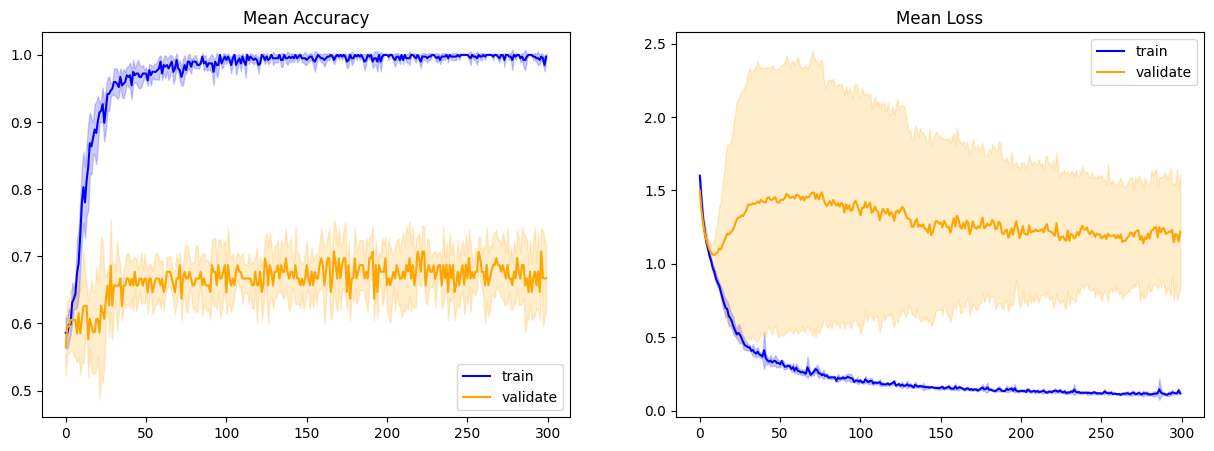

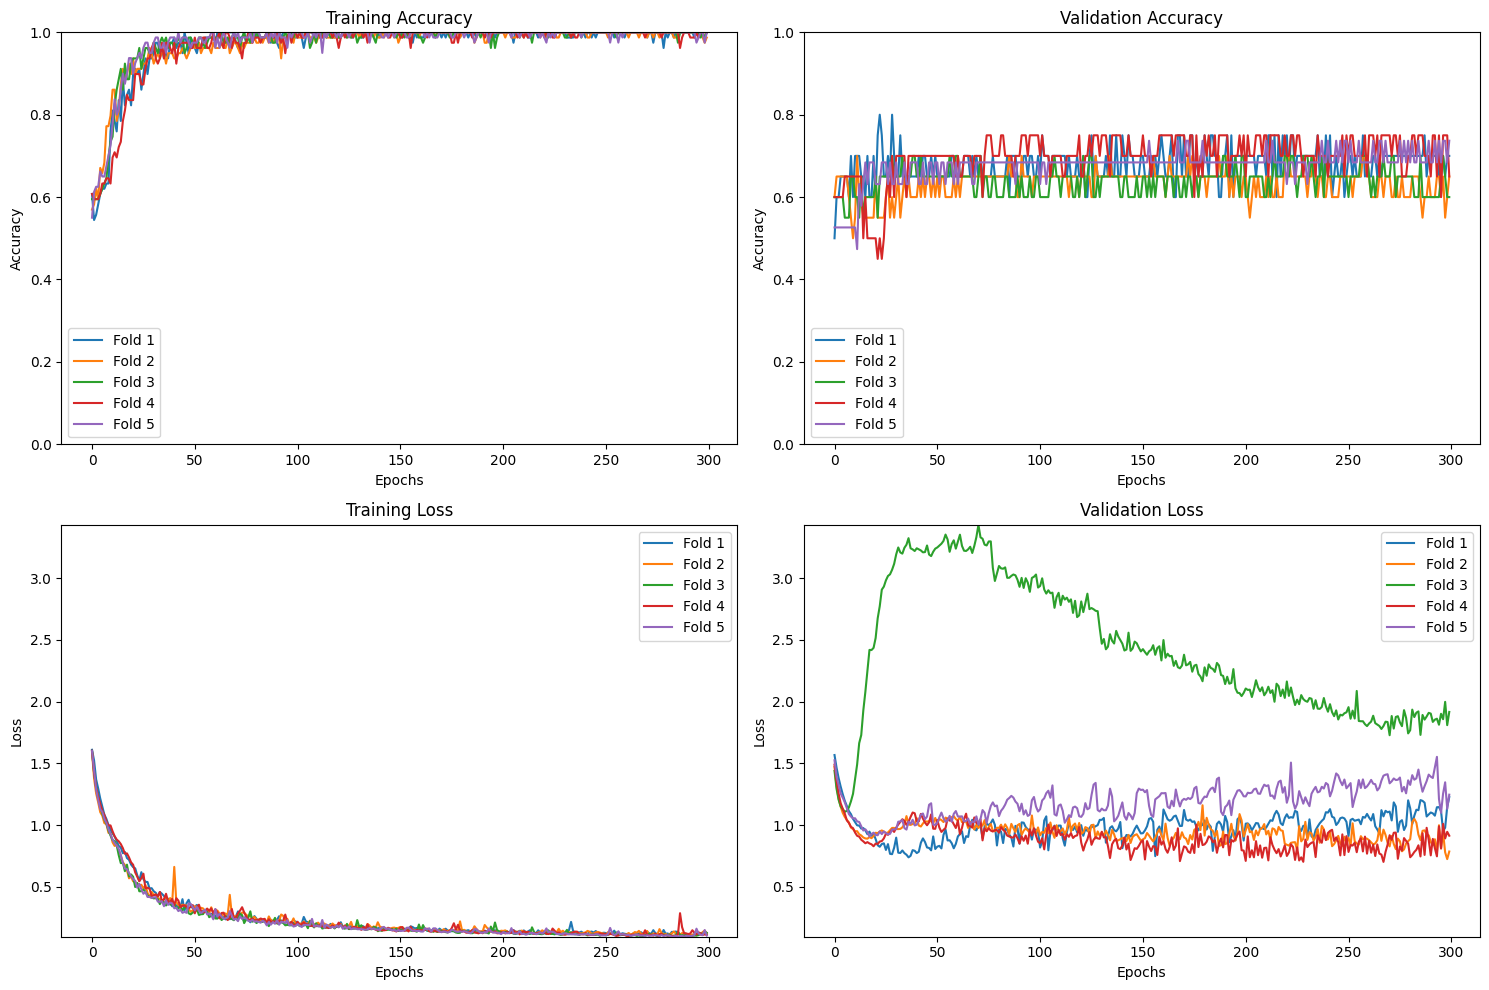

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
predicted classes:       [0 1 1 1 1 0 0 1 1 0 1 1 1 0 1 1 0 0 1]
true validation classes: [1 0 1 1 1 0 0 0 1 0 1 1 1 0 0 1 0 0 0]


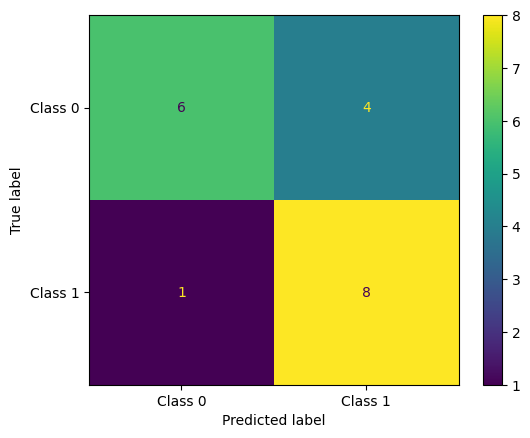

In [115]:
#reset_weights(model4)
mean_acc_DNN_2_val, sd_acc_DNN_2_val = crossvalidate(reduced_df_train, model2, components, target ,kf,300)

### Test

Epoch 1/500


33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9466 - loss: 0.2786 - val_accuracy: 0.8400 - val_loss: 0.9670
Epoch 2/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8689 - loss: 0.3544 - val_accuracy: 0.8400 - val_loss: 0.9945
Epoch 3/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9413 - loss: 0.4092 - val_accuracy: 0.8800 - val_loss: 0.7135
Epoch 4/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9794 - loss: 0.1812 - val_accuracy: 0.9200 - val_loss: 0.5677
Epoch 5/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9670 - loss: 0.2074 - val_accuracy: 0.8400 - val_loss: 0.7664
Epoch 6/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9627 - loss: 0.1938 - val_accuracy: 0.9600 - val_loss: 0.5500
Epoch 7/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9954 - loss: 0.1554 - val_accuracy: 0.9200 - val_loss: 0.5828
Epoch 8/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9771 - loss: 0.1702 - val_accuracy: 0.8800 - val_loss: 0.6

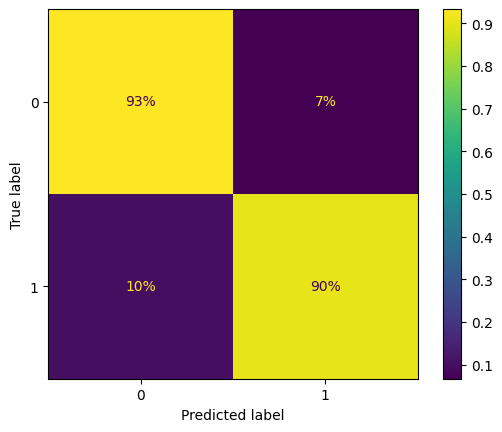

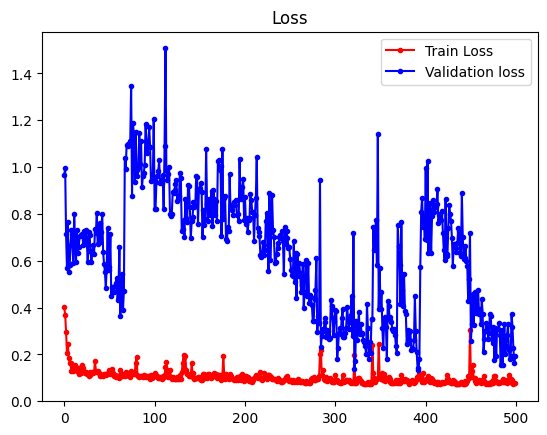

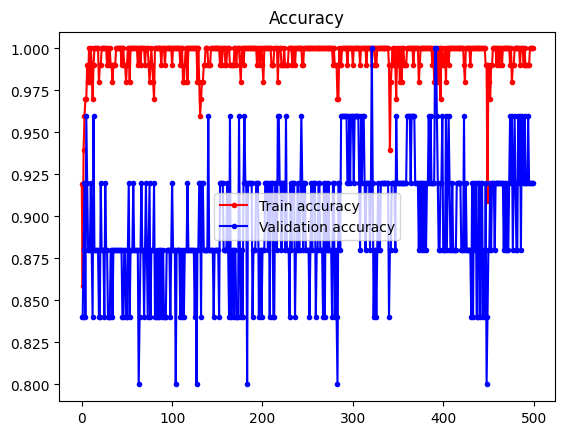

In [116]:
#  reset_weights(model4)
history2 = model2.fit(X_train, y_train, epochs = 500, verbose = 1, shuffle = True, batch_size = 3, validation_data = (X_test, y_test))
acc_DNN_2_test = evaluate_model(model2, history2, X_test, y_test)

## Shallow model

In [117]:
model2_s = Sequential([
    Input(shape=(embeding_dim,)),
    Dense(17, activation='relu', kernel_regularizer=l2(0.01)),
    Dense(2, activation='softmax')
])
model2_s.summary()
model2_s.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])


Model: "sequential_12"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_36 (Dense)                │ (None, 17)             │         1,700 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_37 (Dense)                │ (None, 2)              │            36 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,736 (6.78 KB)

 Trainable params: 1,736 (6.78 KB)

 Non-trainable params: 0 (0.00 B)

Number of classes: 2
training for 1 subset
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 98ms/step - accuracy: 0.7000 - loss: 0.7514
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step
predicted classes:       [0 0 0 1 1 1 0 0 0 0 0 0 1 1 1 0 1 0 1 0]
true validation classes: [0 0 0 1 1 0 0 0 0 0 0 1 1 1 0 1 1 0 0 1]
mean confidence score: 27.7049, sd confidence score: 67.2068
training for 2 subset
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.6500 - loss: 0.6941
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
predicted classes:       [0 1 1 0 1 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0]
true validation classes: [0 0 0 1 1 0 0 1 0 0 0 0 1 1 0 1 0 0 1 0]
mean confidence score: 99.1977, sd confidence score: 376.7516
training for 3 subset
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.7000 - loss: 1.0210
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
predicted classes:       [0 0 0 0 0 0 0 0 1 1 0 0 0 1 1 0 0 1 1 0]
true validation classes: [0 0 1 1 0 1 0 0 0 1 0 0 1 1 1 0 0 0 1 0]
mean confidence score: 76070077.1021, sd confidence score:

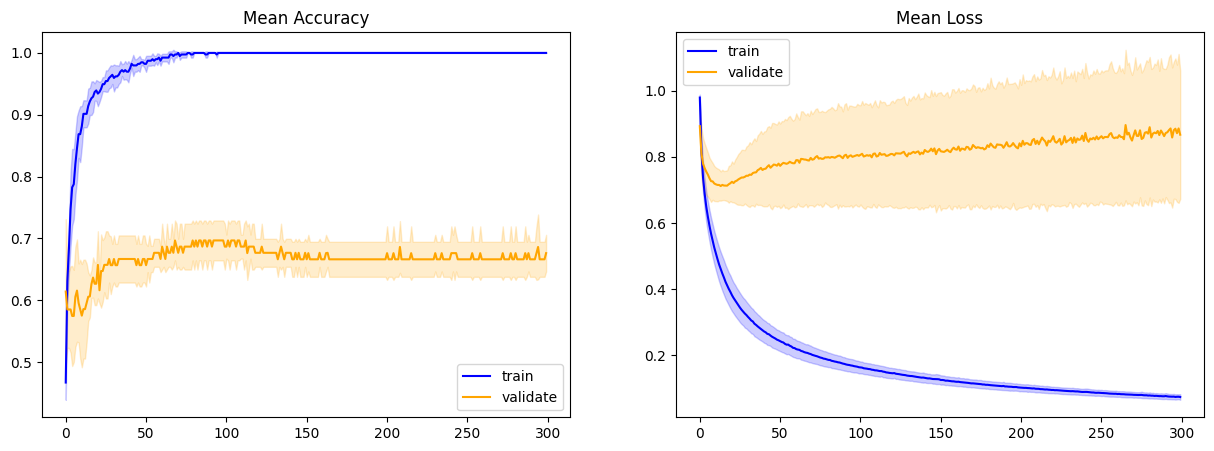

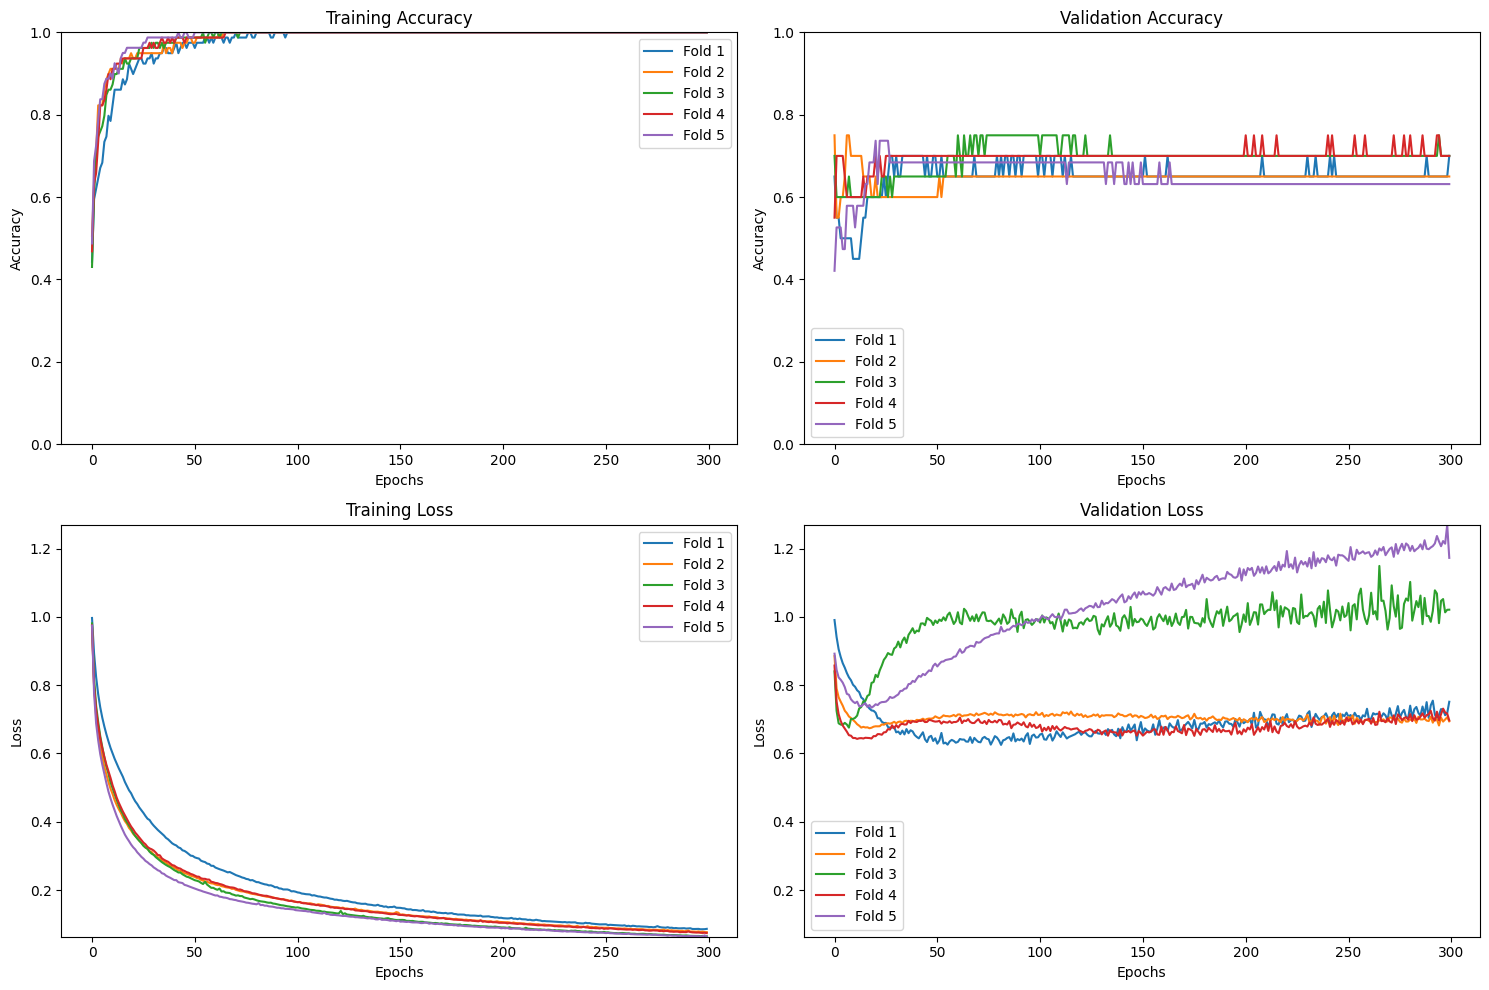

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
predicted classes:       [0 1 1 1 1 1 0 1 1 0 1 1 1 0 1 0 0 0 1]
true validation classes: [1 0 1 1 1 0 0 0 1 0 1 1 1 0 0 1 0 0 0]


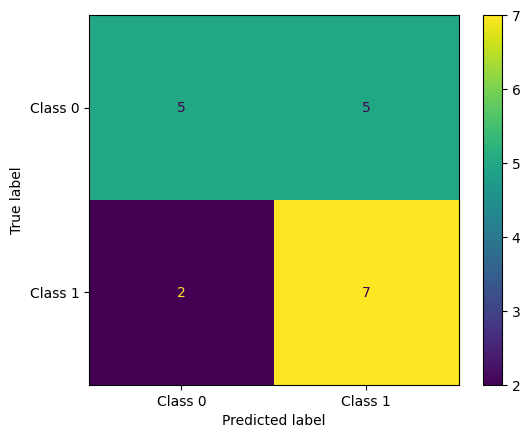

In [118]:
mean_acc_SNN_2_val, sd_acc_SNN_2_val = crossvalidate(reduced_df_train, model2_s, components, target ,kf,300,True)

### test

In [119]:
model2_s.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])   

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 1.0000 - loss: 0.1252
[0.12522529065608978, 1.0]
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step
Predicted values: [0 0 1 0 0 0 0 0 1 1 1 0 1 0 1 0 0 0 1 1 0 0 1 0 1]
True values: [0 0 1 0 0 0 0 0 1 1 1 0 1 0 1 0 0 0 1 1 0 0 1 0 1]
Test accuracy: 0.8799999952316284


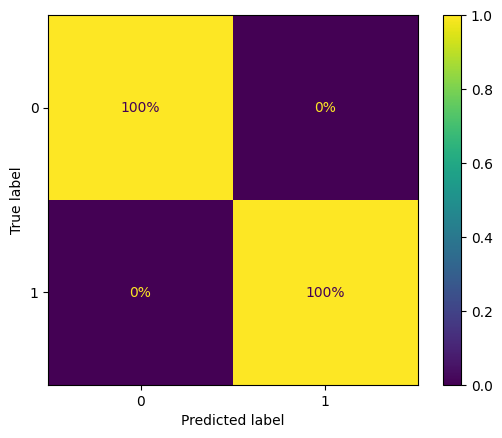

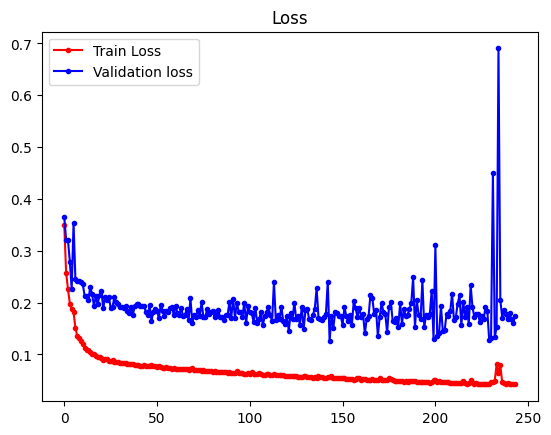

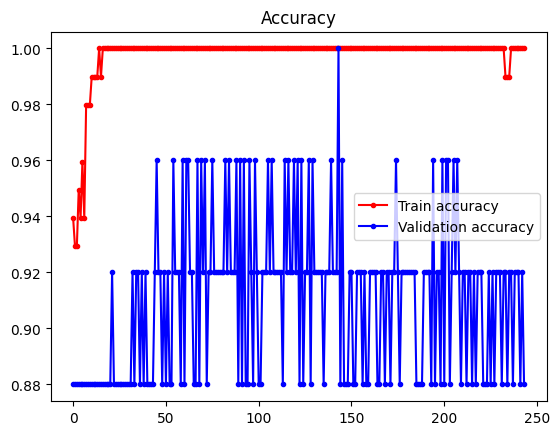

In [120]:
history2_s=model2_s.fit(X_train, y_train, epochs = 500, verbose = 0, shuffle = True, batch_size = 3, validation_data = (X_test, y_test), callbacks = [EarlyStopping(monitor='val_loss', patience=100, restore_best_weights=True)])
acc_SNN_2_test = evaluate_model(model2_s, history2_s, X_test, y_test)

## XGboost

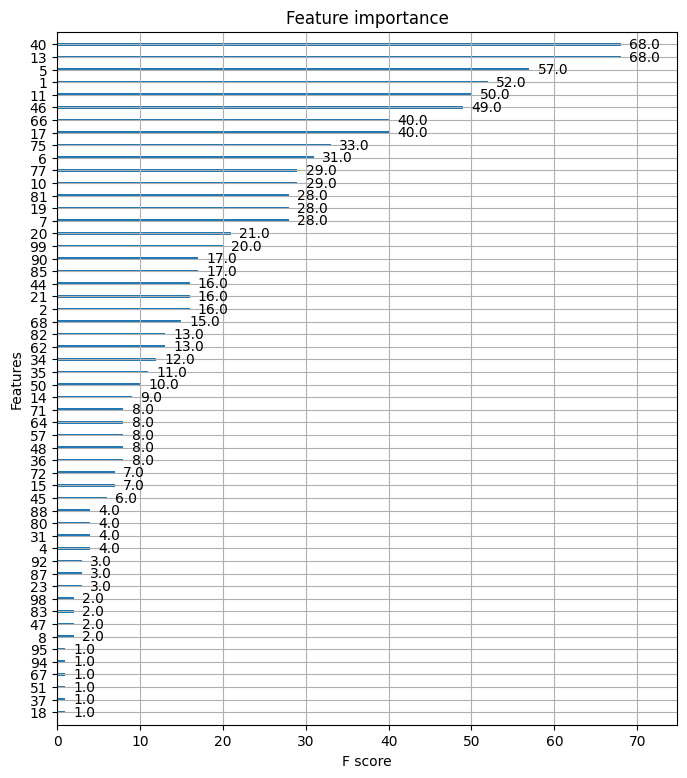

Accuracy0.8
true: [0 0 1 0 0 0 0 0 1 1 1 0 1 0 1 0 0 0 1 1 0 0 1 0 1]
predicted: [0. 1. 1. 0. 0. 0. 0. 0. 1. 0. 1. 1. 1. 0. 1. 0. 0. 0. 0. 1. 0. 0. 0. 0.
 1.]


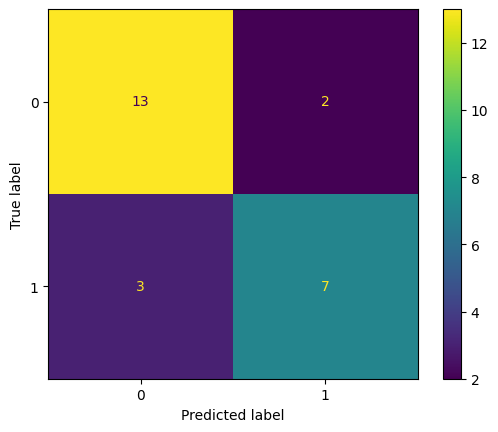

In [121]:
dtrain = xgb.DMatrix(X_train, label=df_train_val[target].values, feature_names=components)  
dtest = xgb.DMatrix(X_test, label=df_test[target].values, feature_names=components)
params = {
    'objective': 'multi:softmax',
    'num_class': 5,
    'max_depth': 3, 
    'eta': 0.1,
    'seed': 111
}

x2 = xgb.train(params, dtrain, num_boost_round=100)

xgb_pred = x2.predict(dtest)
xgb_acc = accuracy_score(df_test[target].values, xgb_pred)
acc_XGB_2_test = xgb_acc
fig, ax = plt.subplots(figsize=(8, 9))
xgb.plot_importance(x2, ax=ax)
plt.show()

print(f"Accuracy{xgb_acc}")
print(f"true: {df_test[target].values}")
print(f"predicted: {xgb_pred}")

cm = confusion_matrix(df_test[target].values, xgb_pred)
ConfusionMatrixDisplay(cm).plot()

# END

In [122]:
print("DNN")
print(f"Accuracy class 5: {round(mean_acc_DNN_5_val,2)}, sd: {round(sd_acc_DNN_5_val,2)}, test: {acc_DNN_5_test}")
print(f"Accuracy class 3: {round(mean_acc_DNN_3_val,2)}, sd: {round(sd_acc_DNN_3_val,2)}, test: {acc_DNN_3_test}")
print(f"Accuracy class 2: {round(mean_acc_DNN_2_val,2)}, sd: {round(sd_acc_DNN_2_val,2)}, test: {acc_DNN_2_test}")
print("SNN")
print(f"Accuracy class 5: {round(mean_acc_SNN_5_val,2)}, sd: {round(sd_acc_SNN_5_val,2)}, test: {acc_SNN_5_test}")
print(f"Accuracy class 3: {round(mean_acc_SNN_3_val,2)}, sd: {round(sd_acc_SNN_3_val,2)}, test: {acc_SNN_3_test}")
print(f"Accuracy class 2: {round(mean_acc_SNN_2_val,2)}, sd: {round(sd_acc_SNN_2_val,2)}, test: {acc_SNN_2_test}")
print("XGB")
print(f"Accuracy class 5: {acc_XGB_5_test}")
print(f"Accuracy class 3: {acc_XGB_3_test}")
print(f"Accuracy class 2: {acc_XGB_2_test}")


DNN
Accuracy class 5: 0.38, sd: 0.05, test: 0.5600000023841858
Accuracy class 3: 0.56, sd: 0.07, test: 0.8399999737739563
Accuracy class 2: 0.67, sd: 0.05, test: 0.9200000166893005
SNN
Accuracy class 5: 0.4, sd: 0.08, test: 0.5199999809265137
Accuracy class 3: 0.61, sd: 0.14, test: 0.800000011920929
Accuracy class 2: 0.68, sd: 0.03, test: 0.8799999952316284
XGB
Accuracy class 5: 0.48
Accuracy class 3: 0.8
Accuracy class 2: 0.8


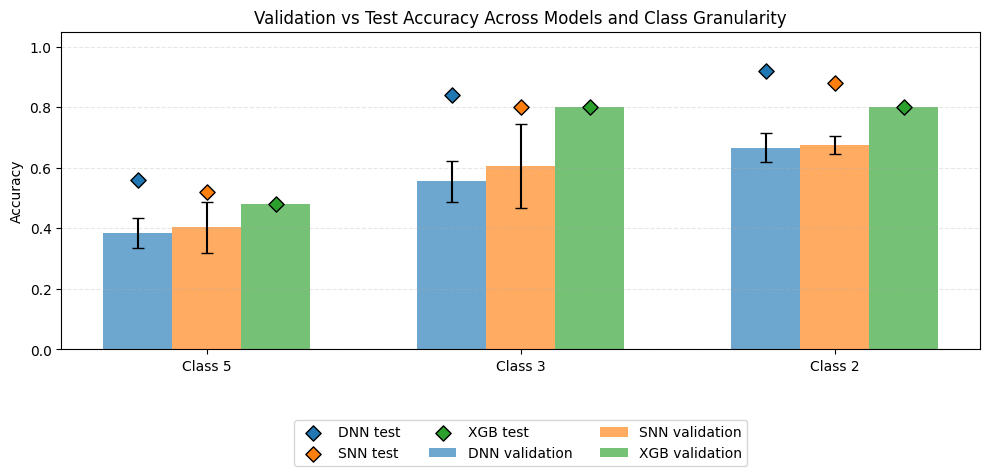

In [123]:
accuracy_rows = [
    ("DNN", "Class 5", mean_acc_DNN_5_val, sd_acc_DNN_5_val, acc_DNN_5_test),
    ("DNN", "Class 3", mean_acc_DNN_3_val, sd_acc_DNN_3_val, acc_DNN_3_test),
    ("DNN", "Class 2", mean_acc_DNN_2_val, sd_acc_DNN_2_val, acc_DNN_2_test),
    ("SNN", "Class 5", mean_acc_SNN_5_val, sd_acc_SNN_5_val, acc_SNN_5_test),
    ("SNN", "Class 3", mean_acc_SNN_3_val, sd_acc_SNN_3_val, acc_SNN_3_test),
    ("SNN", "Class 2", mean_acc_SNN_2_val, sd_acc_SNN_2_val, acc_SNN_2_test),
    ("XGB", "Class 5", acc_XGB_5_test, 0.0, acc_XGB_5_test),
    ("XGB", "Class 3", acc_XGB_3_test, 0.0, acc_XGB_3_test),
    ("XGB", "Class 2", acc_XGB_2_test, 0.0, acc_XGB_2_test),
]

accuracy_df = pd.DataFrame(
    accuracy_rows,
    columns=["Model", "Class", "val_mean", "val_sd", "test_acc"],
)

class_labels = ["Class 5", "Class 3", "Class 2"]
model_order = ["DNN", "SNN", "XGB"]
x_positions = np.arange(len(class_labels))
bar_width = 0.22
palette = {"DNN": "#1f77b4", "SNN": "#ff7f0e", "XGB": "#2ca02c"}

fig, ax = plt.subplots(figsize=(10, 5))
for idx, model in enumerate(model_order):
    subset = accuracy_df[accuracy_df["Model"] == model].set_index("Class").loc[class_labels]
    offsets = x_positions + (idx - (len(model_order) - 1) / 2) * bar_width
    ax.bar(
        offsets,
        subset["val_mean"],
        bar_width,
        yerr=subset["val_sd"],
        capsize=4,
        alpha=0.65,
        color=palette[model],
        label=f"{model} validation",
    )
    ax.scatter(
        offsets,
        subset["test_acc"],
        color=palette[model],
        edgecolors="black",
        marker="D",
        s=60,
        zorder=3,
        label=f"{model} test",
    )

ax.set_xticks(x_positions)
ax.set_xticklabels(class_labels)
ax.set_ylabel("Accuracy")
ax.set_ylim(0, 1.05)
ax.set_title("Validation vs Test Accuracy Across Models and Class Granularity")
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.legend(ncol=3, bbox_to_anchor=(0.5, -0.2), loc="upper center")
plt.tight_layout()
plt.show()

In [124]:
resultsdf = pd.DataFrame(accuracy_rows, columns=["Model", "Class", "val_mean", "val_sd", "test_acc"])
print(resultsdf)
resultsdf.to_csv("results\\Gut_6_NMF_results.csv", index=False)


  Model    Class  val_mean    val_sd  test_acc
0   DNN  Class 5  0.383684  0.049328      0.56
1   DNN  Class 3  0.555263  0.067709      0.84
2   DNN  Class 2  0.667368  0.046975      0.92
3   SNN  Class 5  0.404211  0.084089      0.52
4   SNN  Class 3  0.605789  0.139840      0.80
5   SNN  Class 2  0.676316  0.029586      0.88
6   XGB  Class 5  0.480000  0.000000      0.48
7   XGB  Class 3  0.800000  0.000000      0.80
8   XGB  Class 2  0.800000  0.000000      0.80
